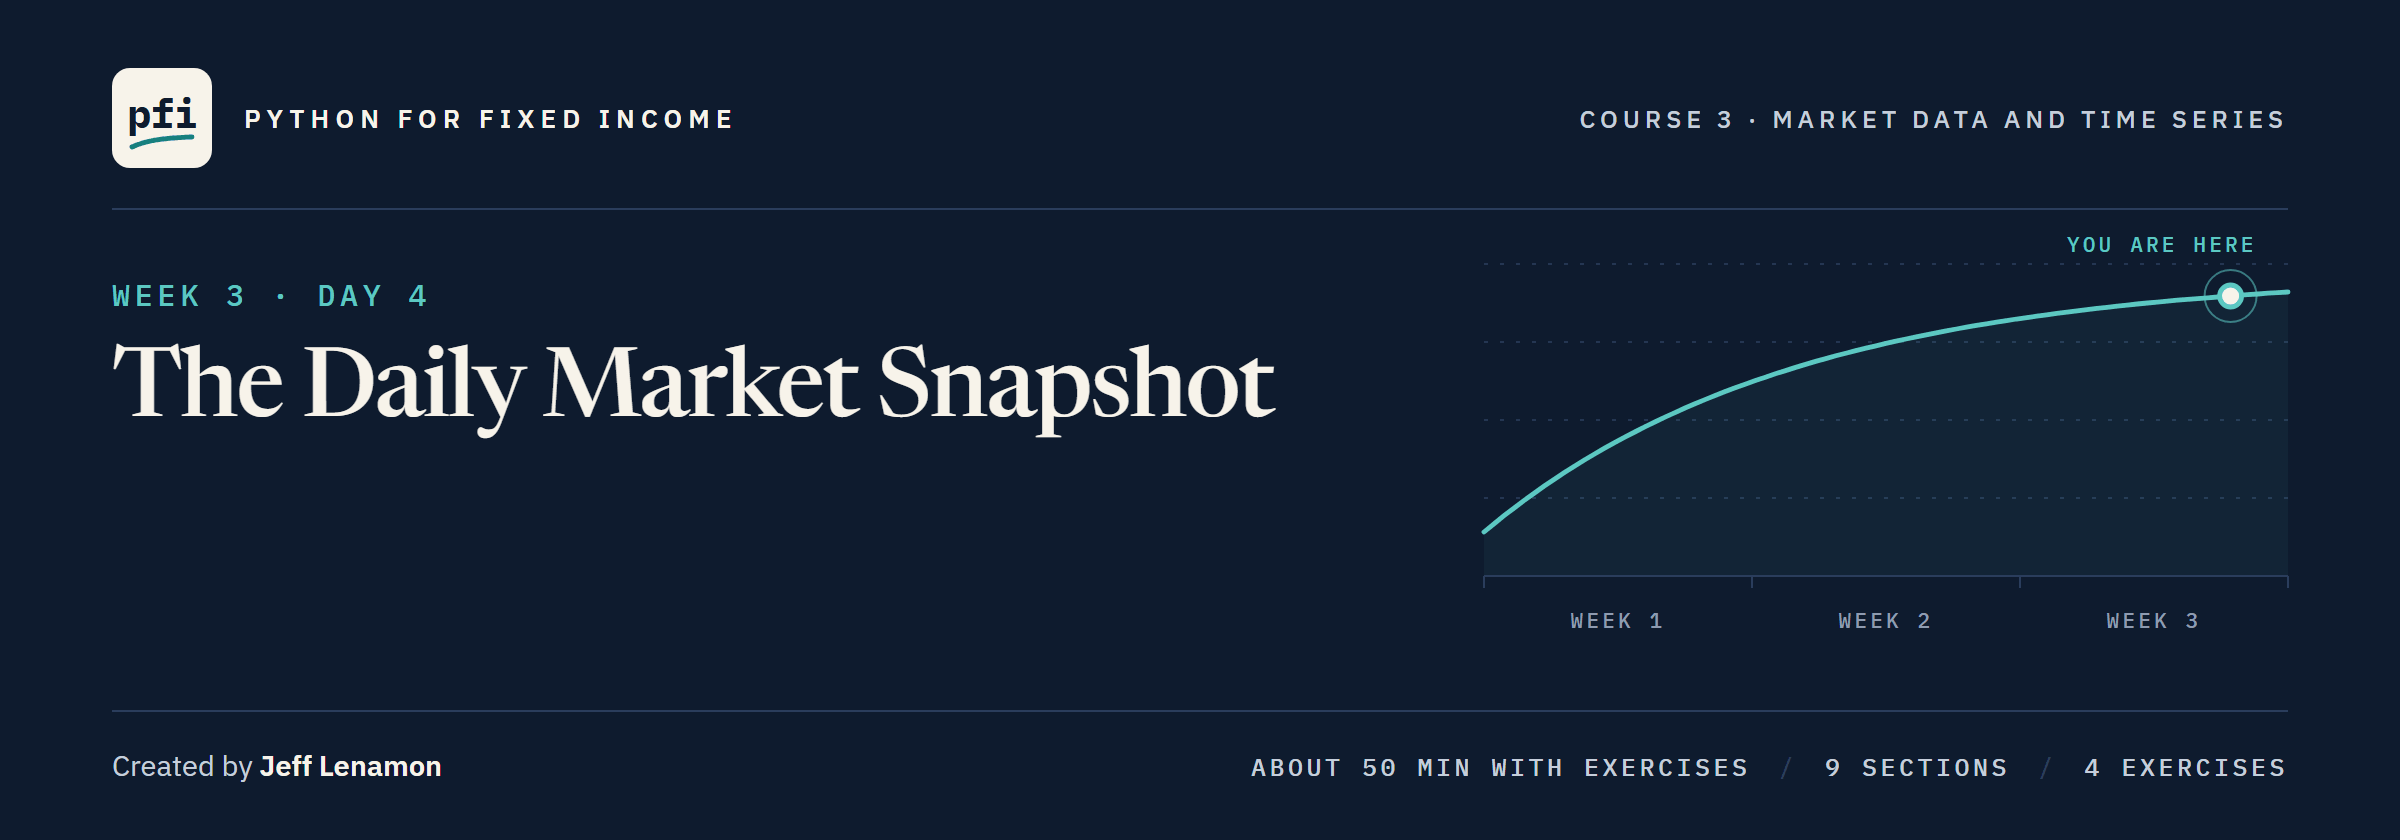

# The Daily Market Snapshot

Week 3, Day 4. One page for one market date: the curve, two synthetic spreads, their shapes, and the book's DV01 with a what-if, written as HTML and as Excel by one command for any date, and never reading past it.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day4/14_the_daily_market_snapshot.ipynb)

### The Desk Lead's Note

> Before every morning meeting I want one page. Where the curve and our two spread series closed on the last market date, how they moved over a day, a week and a month, and where each sits in its own year. The curve's shape. What the day's curve move does to the September book, as a what-if. A web page I can open and a workbook I can check in Excel. Then make it one command for any date, set it to run every morning, and keep the script in our record, never its pages. A page for 30 September shows 30 September, even when the file runs on.

The spreads, the book and its issuers are synthetic.
Every sentence on the page describes, and none forecasts.
Every number comes from the course's files, so there is no key and no live cell.

**Today the course's measures become one page, for any date, from one command.**

### Today's Work Folder

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 13 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(14)

Work folder pfi_course3_14_k4w7q2xr: 8 data files, Course 2's bondmath.py, marketdata.py as notebook 13 left it, 13 commits, tagged week1 and week2


### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...................................................                      [100%]
51 passed in 0.50s



### Imports and the Market

Q. What does the page read?
`validate='one_to_one'` stops the join if a date repeats on either side, as notebook 12 checked its joins.

In [3]:
import importlib
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module as notebook 13 left it, in the work folder
import marketdata as md

In [4]:
# the Treasury file (percent) joined to the synthetic spreads (bp), one row per market date
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
market = treasury.join(spreads, validate='one_to_one')
print(f'{len(market):,} rows, {market.index[0]:%Y-%m-%d} to {market.index[-1]:%Y-%m-%d}, '
      f'{market.shape[1]} columns')

2,940 rows, 2015-01-02 to 2026-10-02, 16 columns


## Your Route Through Day 4

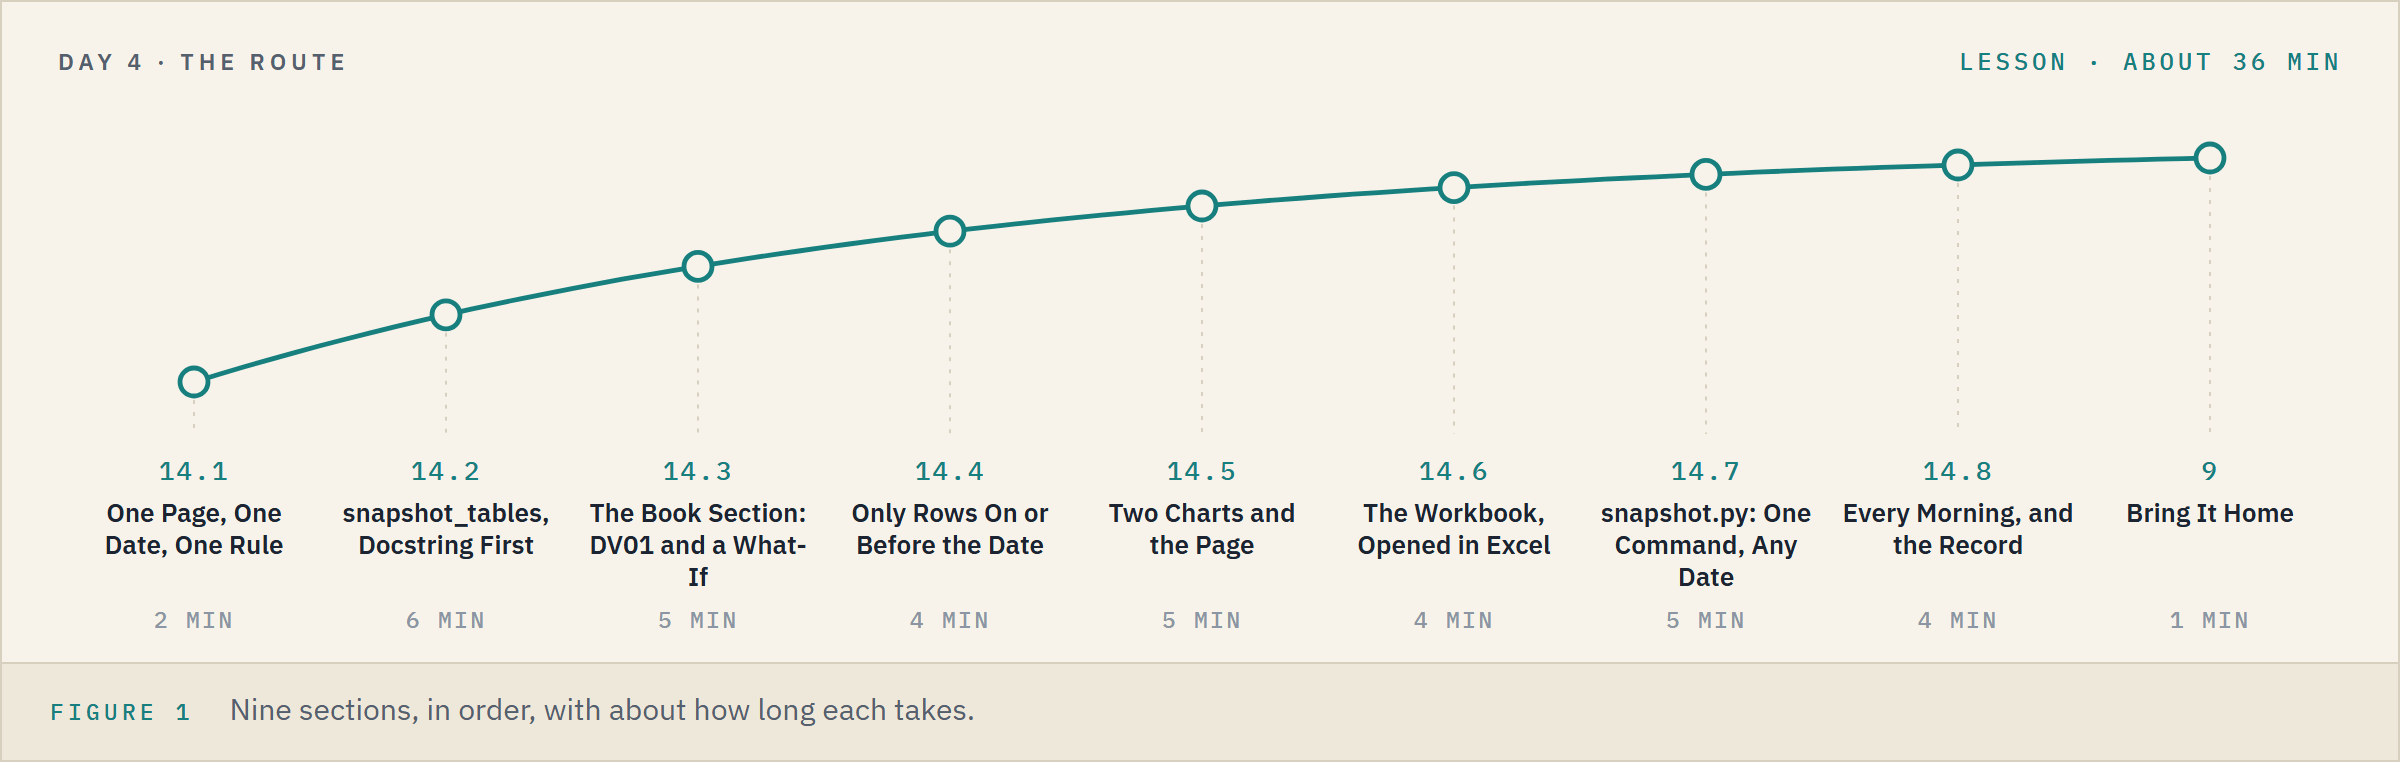

**Time.** About 36 minutes for the lesson, then about 12 for the four exercises.

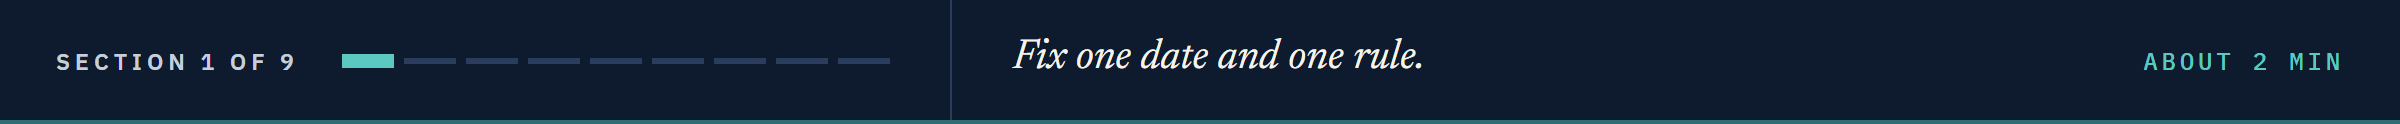

## 14.1 One Page, One Date, One Rule

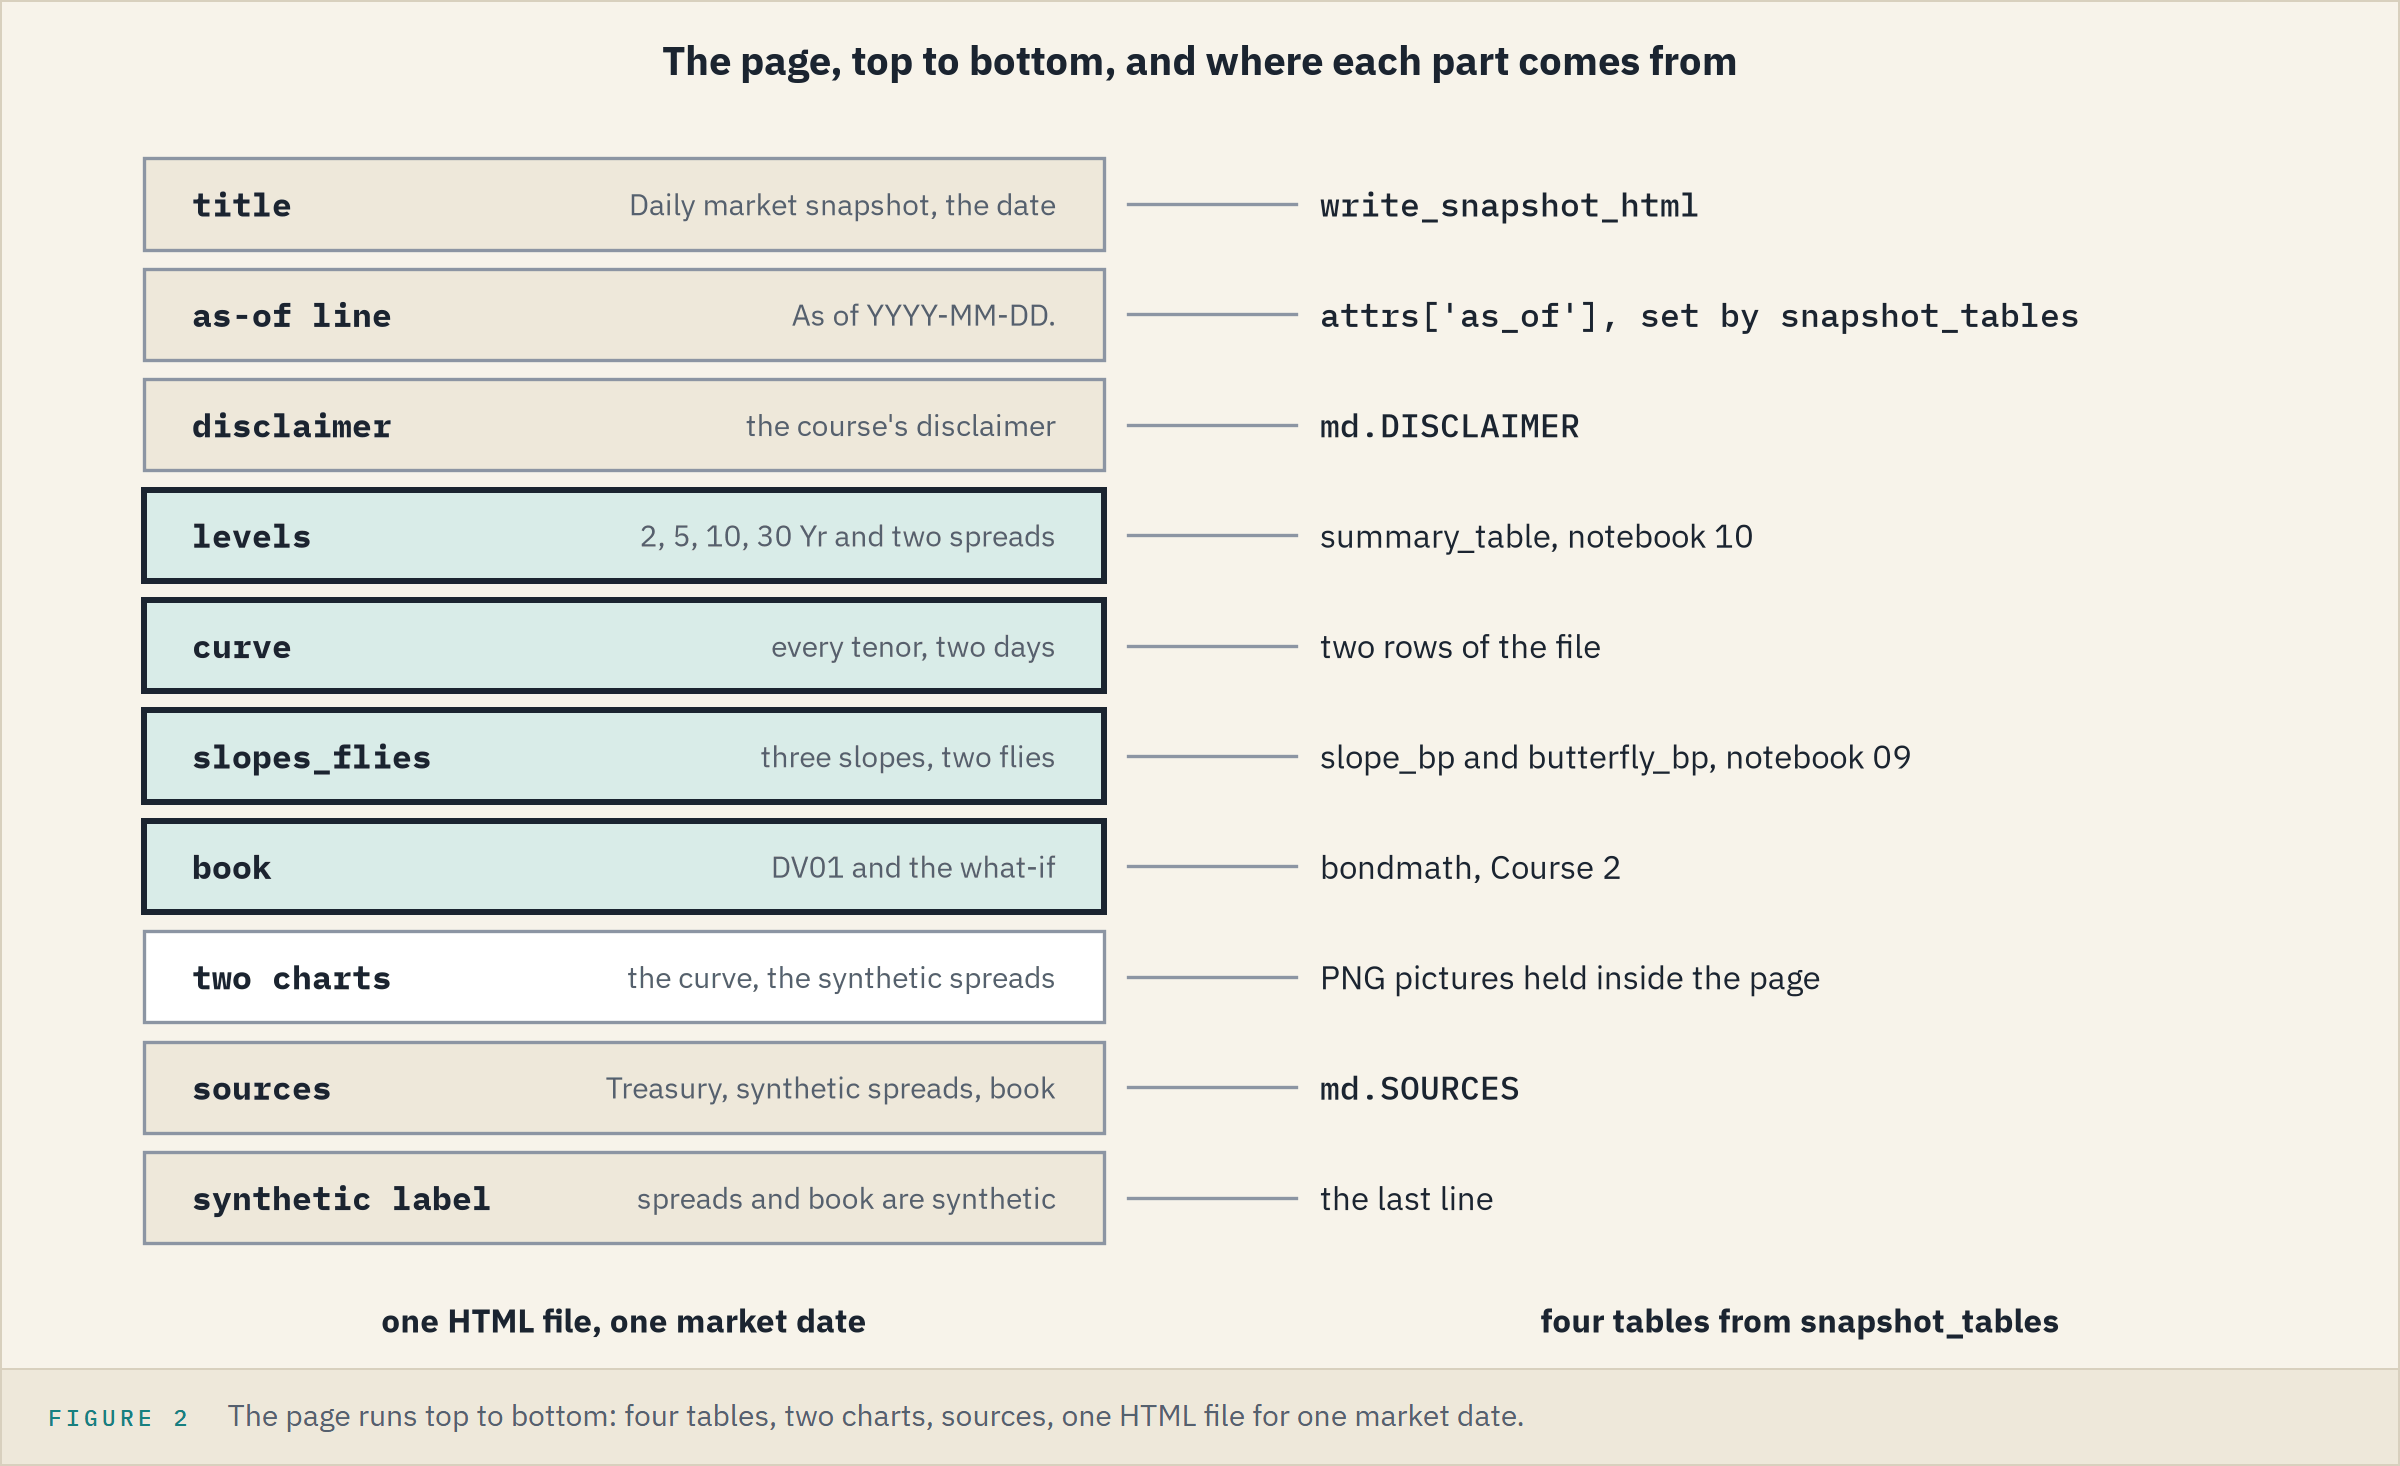

The note's page, top to bottom, each part tagged with where it comes from.
Three weeks of `marketdata` feed it, and Course 2's `bondmath` prices the book.

Every line on it obeys notebook 08's rule.

<table align="left">
<tr><th align="left">Describes</th><th align="left">Never</th></tr>
<tr><td align="left">was, rose, fell, over a day, a week, a month</td><td align="left">will, expect, should</td></tr>
<tr><td align="left">a z-score over 252 rows, today included</td><td align="left">stretched, due to revert</td></tr>
<tr><td align="left">the share of the window at or below today</td><td align="left">cheap, rich, a signal</td></tr>
<tr><td align="left">what the book would do if the curve moved so, labelled a what-if</td><td align="left">what the book will do</td></tr>
</table>
<br clear="left">

### The September Book

In [5]:
# 200 synthetic bonds, priced on 30 September
book = pd.read_csv('holdings.csv')
# the levels table's columns and their units, as notebook 10's units dictionary
SNAPSHOT_UNITS = {'2 Yr': 'pct', '5 Yr': 'pct', '10 Yr': 'pct', '30 Yr': 'pct',
                  'ig_spread_bp': 'bp', 'hy_spread_bp': 'bp'}
print(len(book), 'bonds as of', book['as_of_date'].iloc[0])

200 bonds as of 2026-09-30


**One date, four tables, two charts, and one rule: every number says where something was, never where it goes.**

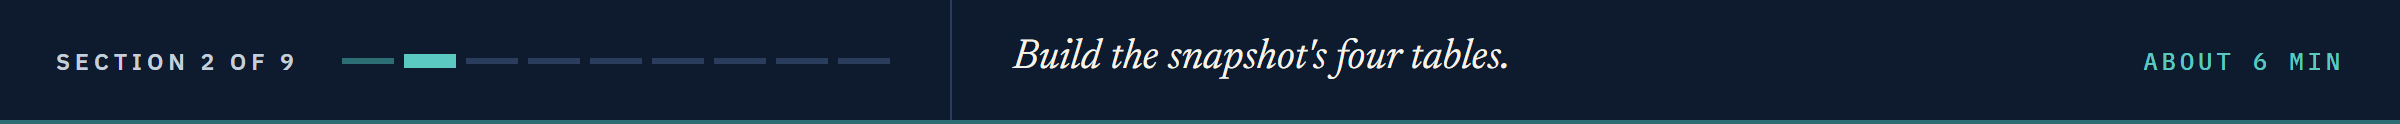

## 14.2 `snapshot_tables`, Docstring First

`snapshot_tables(market, book, as_of, units)` returns four tables for one date, each from rows on or before it.

`known = market.loc[:as_of]`, notebook 10's cut.

`levels`, notebook 10's `summary_table` of the columns in `units`.

`curve`, every tenor on `as_of` and on the row before, with the change in bp.

`slopes_flies`, notebook 09's slopes and flies, summarised the same way.

`book`, the September book's DV01 and a what-if, from a helper that 14.3 reads.

### The Constants and the Book Helper

Today's imports sit where today's code starts, as in notebook 13.
The leading underscore marks `_book_section` as a helper, as notebook 03's `_check_index`.
`book.itertuples()` gives each row as an object, so `bond.coupon` is that row's coupon.
`.agg(**sums)` hands the dictionary `sums` over as named arguments, one per column of the result.

In [6]:
%%writefile -a marketdata.py


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]

Appending to marketdata.py


`reset_index(names='group')` turns the row labels into a column named `group`.
`rating.rstrip('+-')` cuts `+` and `-` off the end, as Course 2's `.str.rstrip`, so `BBB+` becomes `BBB`.

### `snapshot_tables`

`*legs` hands a tuple over as separate arguments, the short leg, the belly and the long leg.

In [7]:
%%writefile -a marketdata.py


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables

Appending to marketdata.py


### 2 October, Four Tables

Each table carries `attrs`, a dictionary of facts about the table itself.
`attrs['as_of']` holds the date, and the writers read it from there.

In [8]:
# reload: the file on disk gained snapshot_tables
importlib.reload(md)
AS_OF = '2026-10-02'
tables = md.snapshot_tables(market, book, AS_OF, SNAPSHOT_UNITS)
print(list(tables), 'as of', tables['levels'].attrs['as_of'])

['levels', 'curve', 'slopes_flies', 'book'] as of 2026-10-02


### The Levels Table

In [9]:
# notebook 10's summary_table, two decimals, the percentile rank shaded
tables['levels'].style.format(precision=2).background_gradient(
    subset=['pct_rank'], cmap='Greens', vmin=0, vmax=100)

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
2 Yr,pct,4.83,5.00,2.00,44.00,2.51,98.02
5 Yr,pct,5.06,5.00,8.00,52.00,2.80,99.60
10 Yr,pct,5.28,4.00,11.00,49.00,3.08,99.60
30 Yr,pct,5.63,2.00,14.00,36.00,3.08,99.60
ig_spread_bp,bp,97.00,-1.00,1.10,1.90,0.22,61.11
hy_spread_bp,bp,328.70,-1.30,11.20,0.10,0.90,73.81


The 10 Yr closed at 5.28 percent, 4 bp up on the day and 49 bp on the month.
Its z-score is 3.08, with 99.6 percent of its last 252 rows at or below it.

### Against Excel's Reference Row

In [10]:
# Excel's answers for the date, from the reference file notebook 06 first read
reference = pd.read_csv('course3_excel_reference.csv', parse_dates=['date'], index_col='date',
                        float_precision='round_trip')
for name, table, row in [('10y', 'levels', '10 Yr'), ('2s10s', 'slopes_flies', '2s10s')]:
    mine, excel = tables[table].loc[row], reference.loc[AS_OF]
    print(f"{row}: z-score gap {abs(mine['zscore'] - excel[f'zscore252_{name}']):.1e}, "
          f"rank gap {abs(mine['pct_rank'] - excel[f'pctrank252_{name}']):.1f}")

10 Yr: z-score gap 4.6e-13, rank gap 0.0
2s10s: z-score gap 1.1e-15, rank gap 0.0


**Excel side by side.** The 10 Yr's last 252 values in A1:A252, today in A252.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Z-score</td><td align="left"><code>tables['levels'].loc['10 Yr', 'zscore']</code></td><td align="left"><code>=STANDARDIZE(A252,AVERAGE(A1:A252),STDEV.S(A1:A252))</code></td><td align="left">3.075234</td></tr>
<tr><td align="left">Percentile rank</td><td align="left"><code>tables['levels'].loc['10 Yr', 'pct_rank']</code></td><td align="left"><code>=COUNTIF(A1:A252,"&lt;="&amp;A252)/COUNT(A1:A252)*100</code></td><td align="left">99.603175</td></tr>
</table>
<br clear="left">

### The Curve's Move

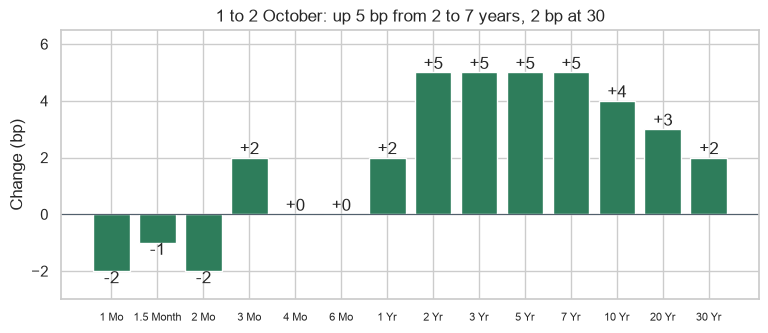

In [11]:
# the day's change by tenor, in bp, one labelled bar each
curve = tables['curve']
fig, ax = plt.subplots(figsize=(9, 3.5))
bars = ax.bar(curve.index, curve['chg_bp'])
ax.bar_label(bars, fmt='%+.0f')
ax.axhline(0, color='#52606D', linewidth=0.8)
ax.set_title('1 to 2 October: up 5 bp from 2 to 7 years, 2 bp at 30')
ax.set_ylabel('Change (bp)')
ax.set_ylim(-3, 6.5)
ax.tick_params(axis='x', labelsize=8)  # smaller labels, so all 14 tenors fit
plt.show()

### Slopes and Flies

In [12]:
# notebook 09's shapes in bp, summarised as the levels are
tables['slopes_flies'].style.format(precision=2)

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
2s10s,bp,45.00,-1.00,9.00,5.00,-0.51,28.17
5s30s,bp,57.00,-3.00,6.00,-16.00,-2.07,5.95
3m10y,bp,109.00,2.00,16.00,22.00,2.07,100.00
2s5s10s,bp,1.00,1.00,3.00,11.00,2.70,98.81
5s10s30s,bp,-13.00,1.00,0.00,10.00,2.58,100.00


2s10s is 45 bp, with 28.2 percent of its year at or below it, and 5s30s 57 bp at 5.95 percent.

**One call builds three of the page's tables for 2 October, and the 10 Yr's z-score ties to Excel's within 4.6e-13.**

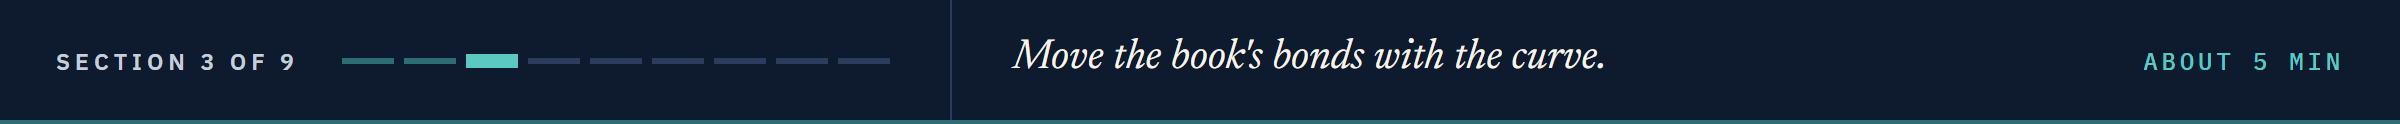

## 14.3 The Book Section: DV01 and a What-If

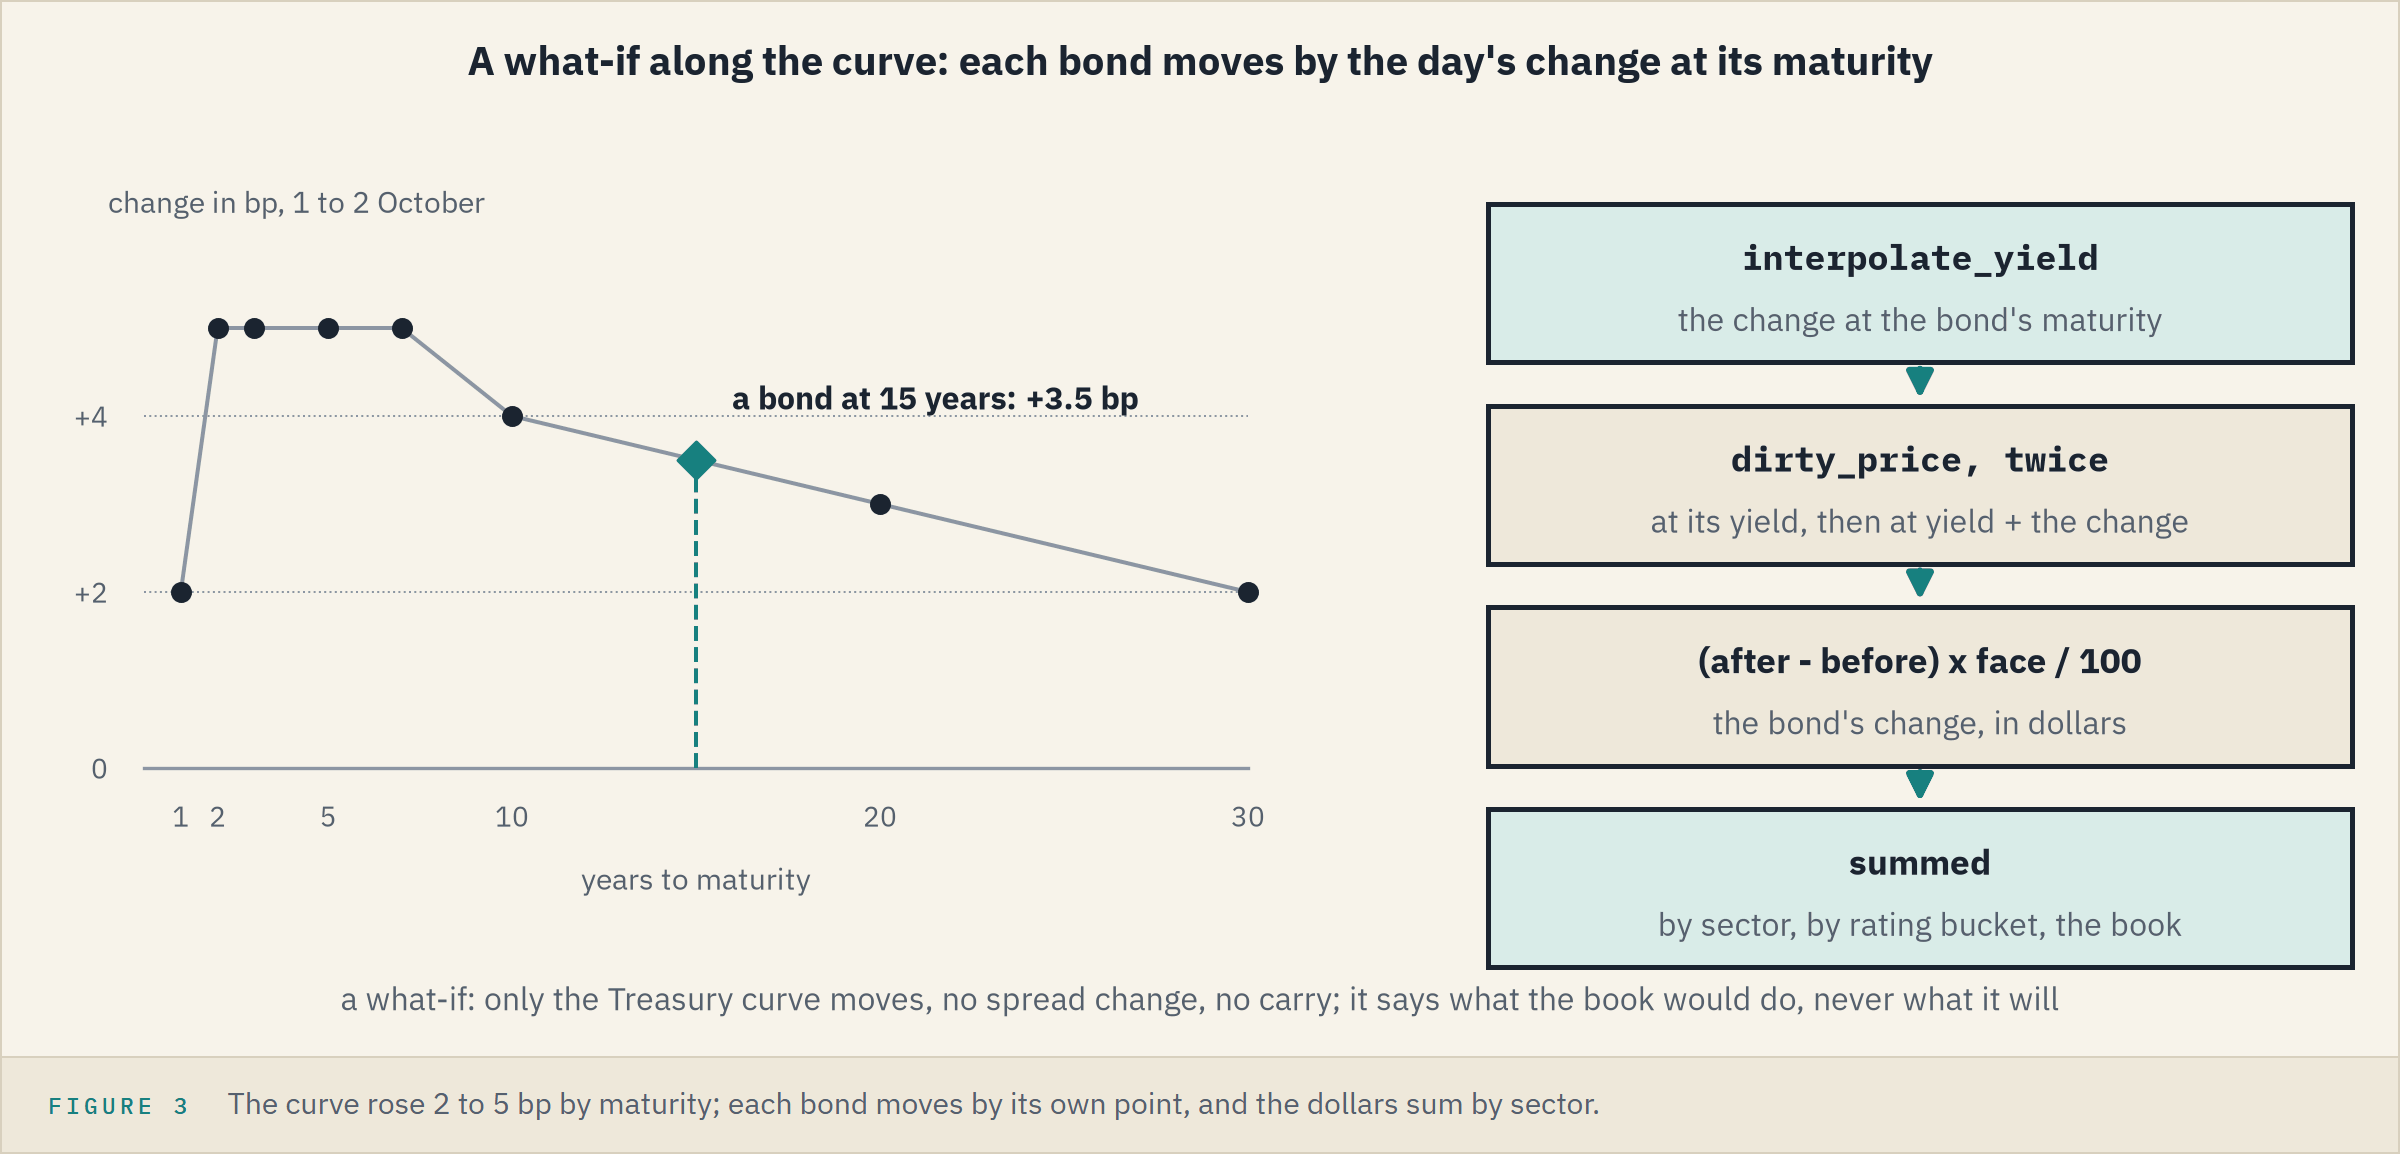

The fourth table moves each bond's yield by the day's curve change at its maturity, Course 2's `interpolate_yield`, and prices it again.
It is a what-if, not a forecast.
Only the Treasury curve moves, with no spread change and no carry.
The prices are 30 September's and the move is 2 October's.
Course 2's notebook 14 moved every yield by the same amount, and here the move differs by maturity.

### DV01 by Sector and Bucket

In [13]:
# the book table without its what-if column; money in dollars, DV01 in dollars per bp
money = ['face_usd', 'market_value_usd', 'dv01_usd']
dv01_table = tables['book'].drop(columns='mv_change_usd')
dv01_table.style.format('{:,.2f}', subset=money).hide(axis='index')

by,group,bonds,face_usd,market_value_usd,dv01_usd
sector,Consumer,26,"56,250,000.00","56,629,597.50","39,489.93"
sector,Energy,17,"39,250,000.00","38,830,005.00","23,542.53"
sector,Financials,26,"69,250,000.00","68,219,672.50","42,434.63"
sector,Health Care,20,"39,000,000.00","38,908,187.50","19,941.82"
sector,Industrials,20,"50,750,000.00","52,540,745.00","35,177.59"
sector,Materials,26,"70,500,000.00","71,701,617.50","37,739.11"
sector,Technology,12,"30,000,000.00","30,311,760.00","16,572.55"
sector,Telecom,21,"54,750,000.00","55,848,270.00","34,384.38"
sector,Transportation,20,"50,000,000.00","48,822,897.50","39,971.07"
sector,Utilities,12,"29,250,000.00","29,006,462.50","17,742.51"


**Predict 1**

Q. The book's DV01 is 306,996.11 dollars per bp, and the curve rose 2 to 5 bp from the 1 Yr out. Move each bond's yield by the change at its maturity and price it again: by how many dollars does the book's value change? Write down a number.

### The What-If, in Dollars and in bp

In [14]:
# the last row is the whole book
total = tables['book'].iloc[-1]
print(f"what-if change in value: {total['mv_change_usd']:,.2f} dollars")
# dollars over dollars per bp: the move, in bp of DV01
average_move_bp = -total['mv_change_usd'] / total['dv01_usd']
print(f'{average_move_bp:.2f} bp of DV01')

what-if change in value: -1,193,297.89 dollars
3.89 bp of DV01


The DV01, 306,996.11 dollars per bp, is Course 2's number for the same book.
3.89 bp sits inside the day's +2 to +5 bp, nearer the 5.
A full reprice also carries convexity, so the ratio is close to the DV01-weighted move, not equal to it.

### Where It Lands

In [15]:
# each sector's share of the book's DV01 and of the what-if, in percent
by_sector = tables['book'][tables['book']['by'] == 'sector'].set_index('group')
dv01_share = by_sector['dv01_usd'] / total['dv01_usd'] * 100
what_if_share = by_sector['mv_change_usd'] / total['mv_change_usd'] * 100
shares = pd.DataFrame({'share of DV01': dv01_share, 'share of the what-if': what_if_share})
shares.loc[['Financials', 'Transportation']].round(2)

,share of DV01,share of the what-if
group,,
Financials,13.82,15.09
Transportation,13.02,11.29


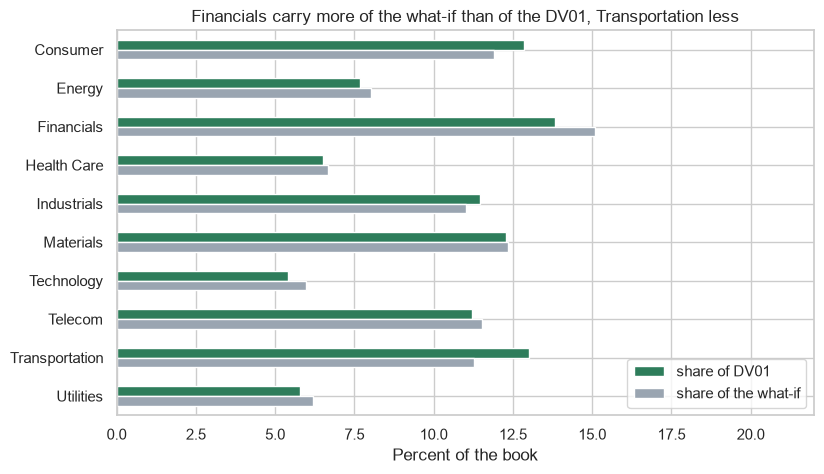

In [16]:
# the two shares side by side, sector by sector
ax = shares.plot.barh(figsize=(9, 5))
# invert_yaxis: the first sector at the top, as the table lists them
ax.invert_yaxis()
ax.set_title('Financials carry more of the what-if than of the DV01, Transportation less')
ax.set_xlabel('Percent of the book')
ax.set_ylabel('')
ax.set_xlim(0, 22)  # room on the right for the legend
ax.legend(loc='lower right')
plt.show()

83 percent of Transportation's DV01 sits beyond 10 years, where the curve rose only 2 to 4 bp.
Weighted by DV01, Transportation's bonds moved 3.4 bp and Financials' 4.3.

### Control Totals

In [17]:
# sectors and buckets each add up to the book, on every column, to the cent
numbers = ['bonds', 'face_usd', 'market_value_usd', 'dv01_usd', 'mv_change_usd']
book_table = tables['book']
for by in ['sector', 'rating bucket']:
    gap = book_table[book_table['by'] == by][numbers].sum() - total[numbers].astype(float)
    assert (gap.abs() < 0.005).all(), by
print('sectors and rating buckets each add to the book on all five columns')

sectors and rating buckets each add to the book on all five columns


**The day's curve move takes 1,193,297.89 dollars off the synthetic book in the what-if, about 3.9 bp of its DV01, and lands less where the long bonds sit.**

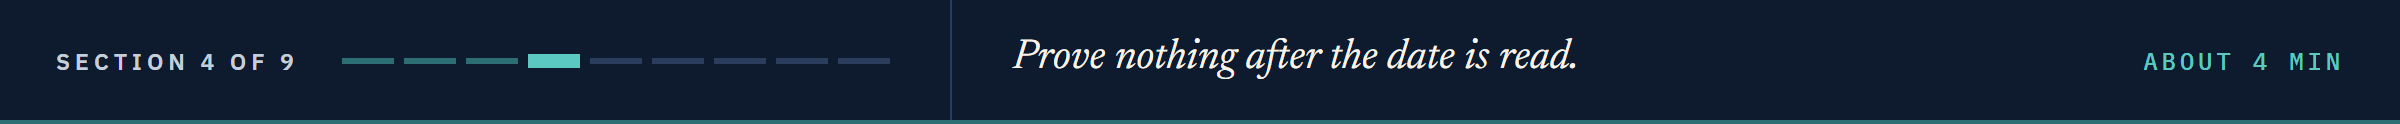

## 14.4 Only Rows On or Before the Date

The note's last line: a page for 30 September shows 30 September.

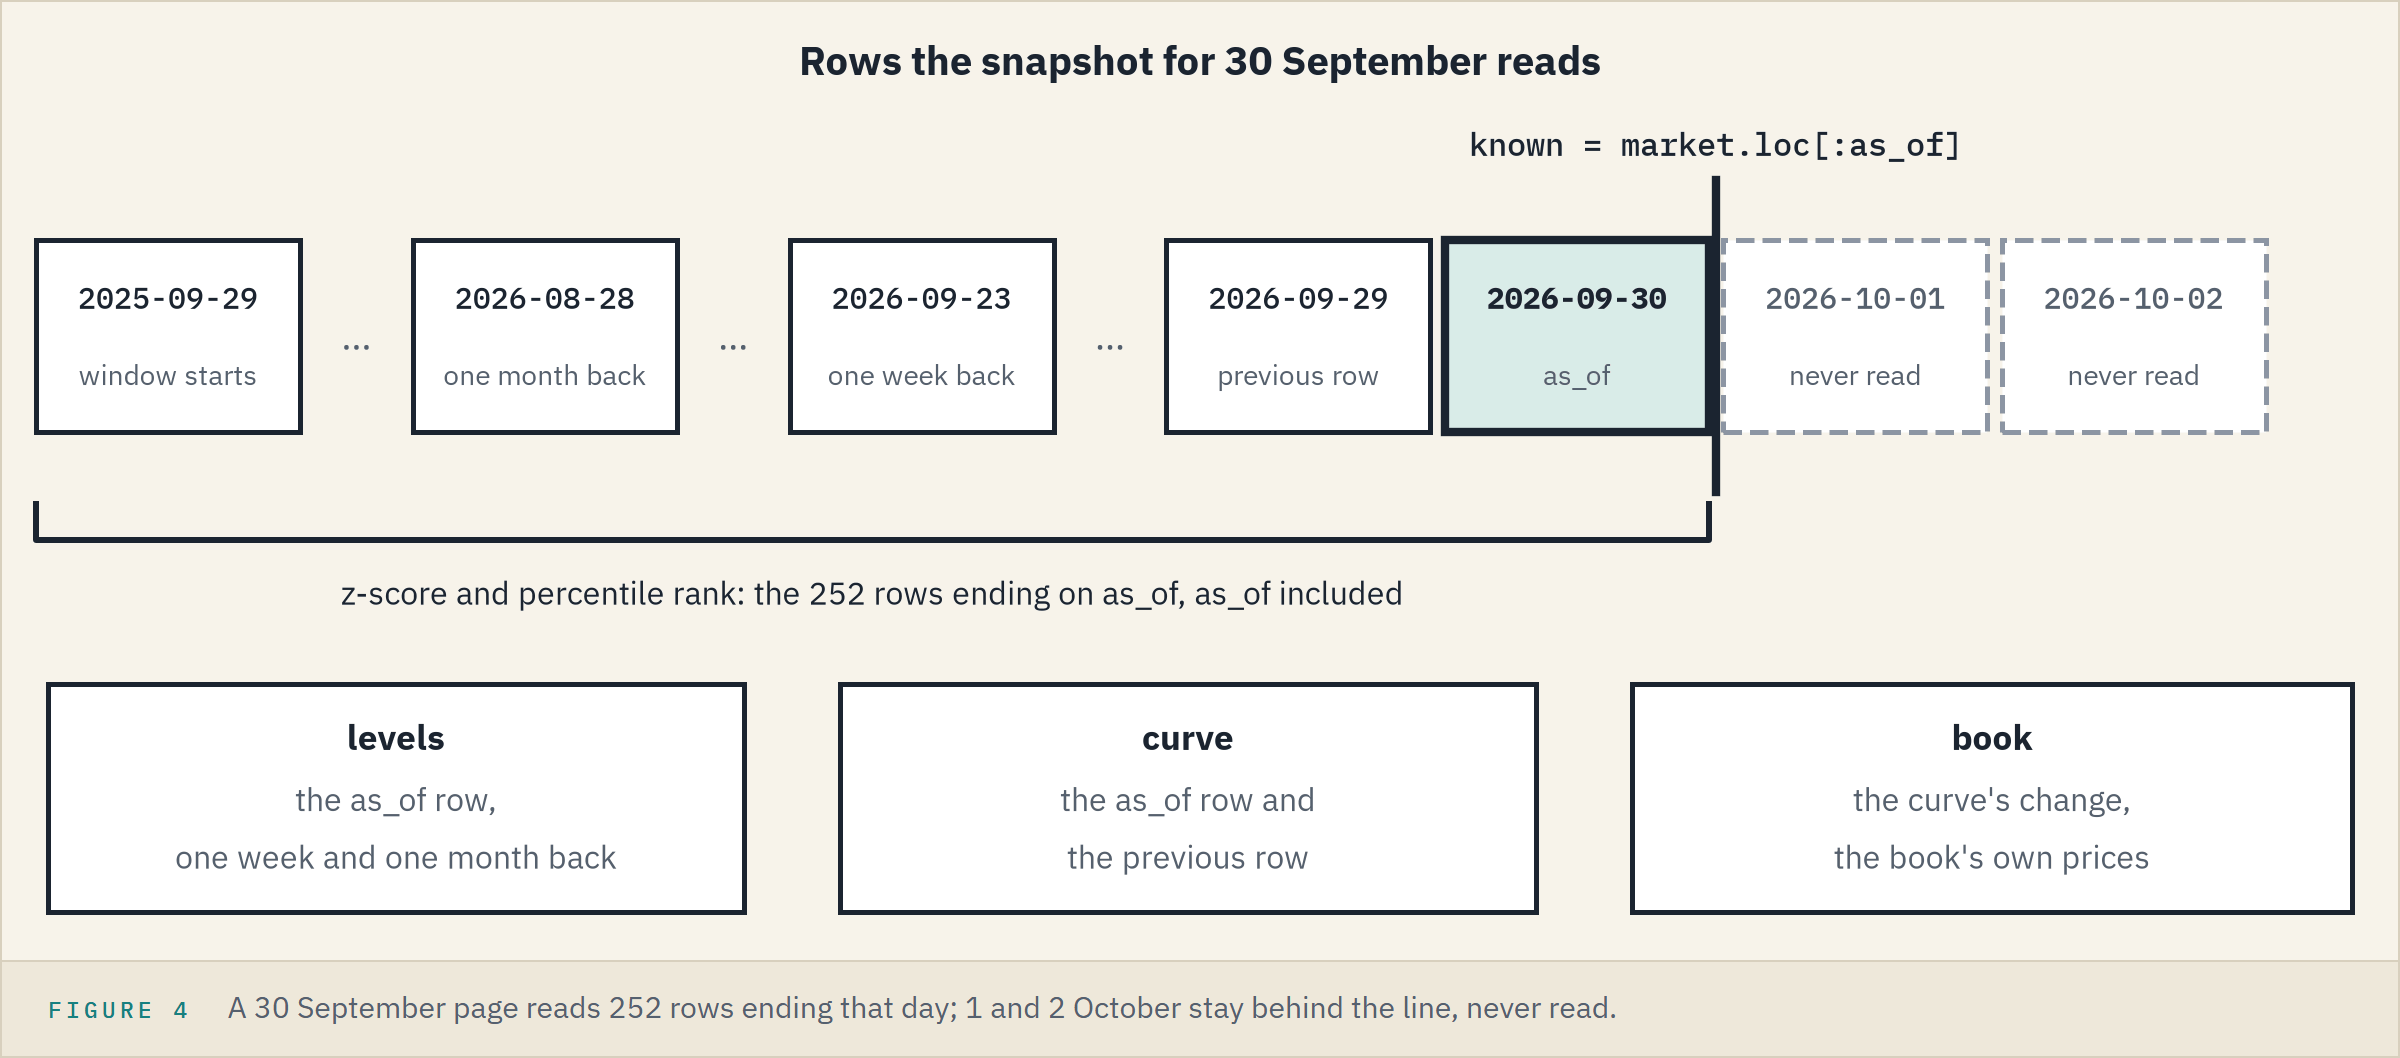

Notebook 10's picture showed the cut.
This one shows which rows behind it each table reads.

### A Date With No Row

In [18]:
# Labor Day 2026: the market was closed, so the file has no row
md.snapshot_tables(market, book, '2026-09-07', SNAPSHOT_UNITS)

ValueError: 2026-09-07 is not a market date: market has no row for it

**Predict 2**

Q. 2015-06-01 has a row, the file's 104th. The z-score and the percentile rank use 252 rows. Its 10 Yr row shows:

A) both from the 104 rows so far
B) the level and the changes, with the z-score and the rank empty
C) the z-score empty, the rank from the rows so far

### Five Months Into the File

In [19]:
# the snapshot for the file's 104th row, and its 10 Yr row
early = md.snapshot_tables(market, book, '2015-06-01', SNAPSHOT_UNITS)
early['levels'].loc['10 Yr']

unit          pct
level        2.19
chg_1d_bp     7.0
chg_1w_bp    -2.0
chg_1m_bp     7.0
zscore        NaN
pct_rank      NaN
Name: 10 Yr, dtype: object

B: the level and the changes, and `NaN` for both window measures, notebook 07's `min_periods`.
A short window never passes for a year.

### 30 September, Cut and Uncut

In [20]:
# the whole file, and the file cut at 30 September: every table must be the same
full = md.snapshot_tables(market, book, '2026-09-30', SNAPSHOT_UNITS)
cut_at = md.snapshot_tables(market.loc[:'2026-09-30'], book, '2026-09-30', SNAPSHOT_UNITS)
for name in full:
    pd.testing.assert_frame_equal(full[name], cut_at[name], check_exact=True)
print(f"four tables equal; the 10 Yr on 30 September: {full['levels'].loc['10 Yr', 'level']:.2f}")

four tables equal; the 10 Yr on 30 September: 5.29


### Two Tests

`snapshot_inputs` loads the market and the book as this notebook does.
The first test asks for 30 September from the full file, the second for Labor Day.

In [21]:
%%writefile -a test_marketdata.py


from matplotlib.figure import Figure  # a chart without a screen, from day 14

# the market columns on the snapshot and their units
SNAPSHOT_UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}


def snapshot_inputs() -> tuple[pd.DataFrame, pd.DataFrame]:
    """The market (the Treasury file joined to the synthetic spreads) and the September book."""
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")
    market = read_treasury().join(spreads, validate="one_to_one")
    return market, pd.read_csv(HERE / "holdings.csv")


def test_snapshot_uses_as_of_not_last_row():
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-09-30", SNAPSHOT_UNITS)
    # the file runs to 2026-10-02, but the snapshot for 2026-09-30 shows 2026-09-30
    assert tables["levels"].loc["10 Yr", "level"] == 5.29
    assert tables["curve"].loc["10 Yr", "as_of_pct"] == 5.29
    assert tables["curve"].loc["10 Yr", "previous_pct"] == market.loc["2026-09-29", "10 Yr"]
    assert tables["levels"].attrs["as_of"] == "2026-09-30"
    total = tables["book"].set_index("by").loc["total"]
    assert total["bonds"] == 200


def test_snapshot_rejects_non_market_date():
    market, book = snapshot_inputs()
    with pytest.raises(ValueError):
        md.snapshot_tables(market, book, "2026-09-07", SNAPSHOT_UNITS)

Appending to test_marketdata.py


In [22]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.....................................................                    [100%]
53 passed in 0.50s



**The snapshot refuses a date the market never had and never reads past its date, and two tests now hold both.**

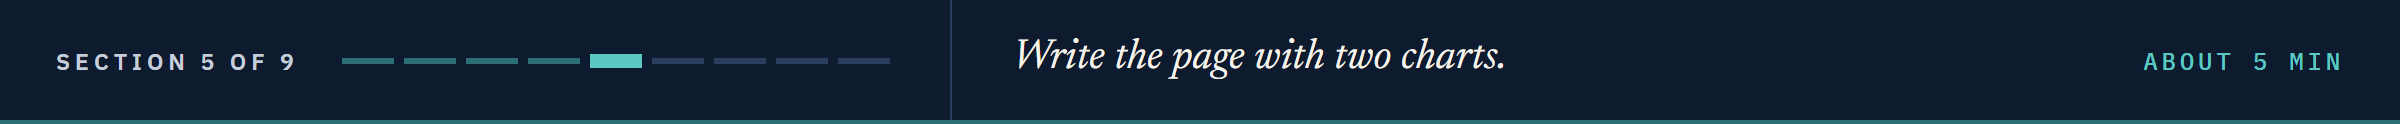

## 14.5 Two Charts and the Page

The note asks for a web page, and the page needs its two charts.

### The Curve on Both Days

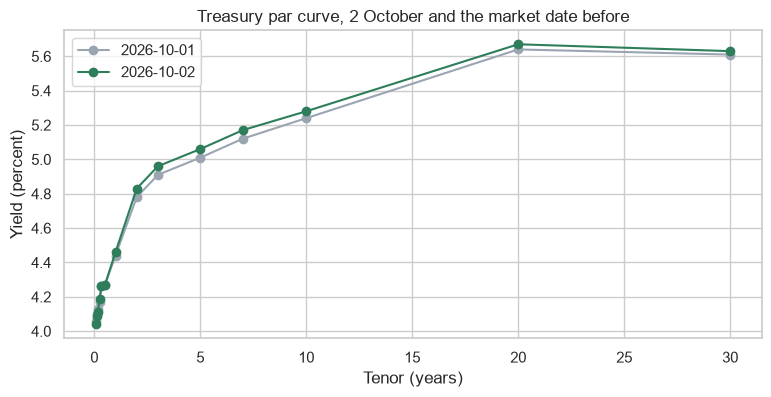

In [23]:
# the curve on both days, kept as curve_figure for the page
curve_figure, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve['years'], curve['previous_pct'], marker='o', color='#9AA5B1', label='2026-10-01')
ax.plot(curve['years'], curve['as_of_pct'], marker='o', color='#2E7D5B', label='2026-10-02')
ax.set_title('Treasury par curve, 2 October and the market date before')
ax.set_xlabel('Tenor (years)')
ax.set_ylabel('Yield (percent)')
ax.legend()
plt.show()

### The Synthetic Spreads, the Last 252 Days

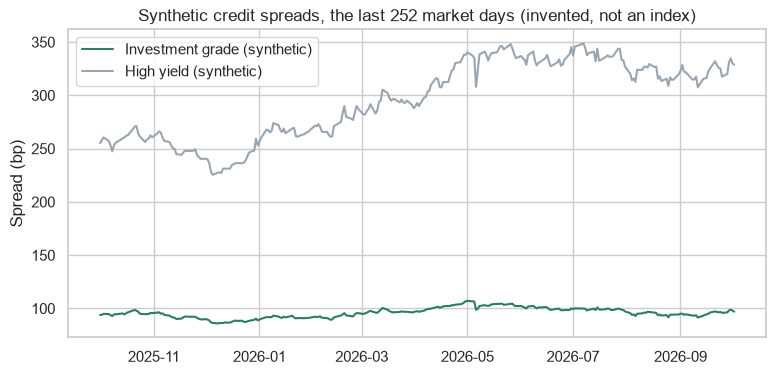

In [24]:
# the two synthetic spreads over the last 252 rows up to the date, kept as spread_figure
recent = market.loc[:AS_OF, ['ig_spread_bp', 'hy_spread_bp']].tail(252)
spread_figure, ax = plt.subplots(figsize=(9, 4))
ax.plot(recent.index, recent['ig_spread_bp'], label='Investment grade (synthetic)')
ax.plot(recent.index, recent['hy_spread_bp'], label='High yield (synthetic)')
ax.set_title('Synthetic credit spreads, the last 252 market days (invented, not an index)')
ax.set_ylabel('Spread (bp)')
ax.legend()
plt.show()

The page takes the chart objects themselves, `curve_figure` and `spread_figure`, which matplotlib calls a `Figure`.

### `write_snapshot_html`

It writes one self-contained page, with every picture inside the file.
`table.to_html(float_format="{:,.2f}".format)` writes a table as HTML, the string's `format` used as a function.
`html.escape` makes text safe for HTML, so `&` is written `&amp;`.

In [25]:
%%writefile -a marketdata.py


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path

Appending to marketdata.py


Each chart goes into `io.BytesIO()`, a file held in memory, as a PNG.
`base64` turns the PNG's bytes into plain text, so the picture sits inside the page as a **data URI**.

### Write the Page

In [26]:
# reload, then write the page into a snapshots folder
importlib.reload(md)
Path('snapshots').mkdir(exist_ok=True)
figures = {'Treasury curve': curve_figure, 'Synthetic credit spreads': spread_figure}
html_path = md.write_snapshot_html(tables, figures, Path('snapshots') / f'snapshot_{AS_OF}.html',
                                   f'Daily market snapshot, {AS_OF}')
print(html_path.name)

snapshot_2026-10-02.html


### The Page

`HTML(text)` marks text as a web page, and `display` shows it here, as a browser would.


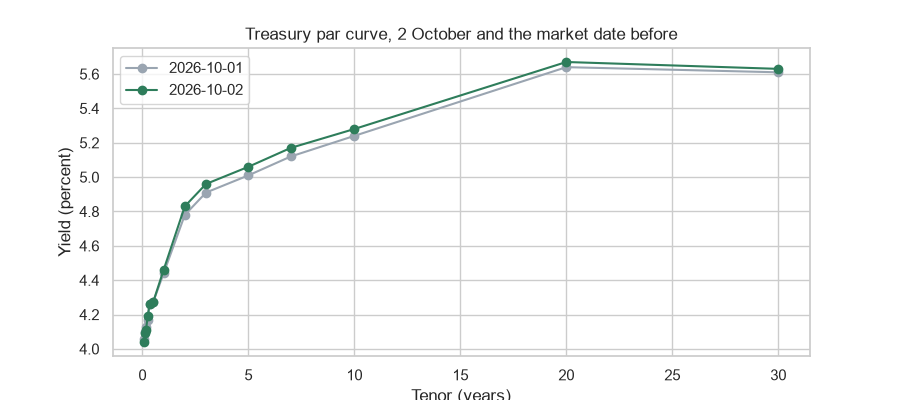
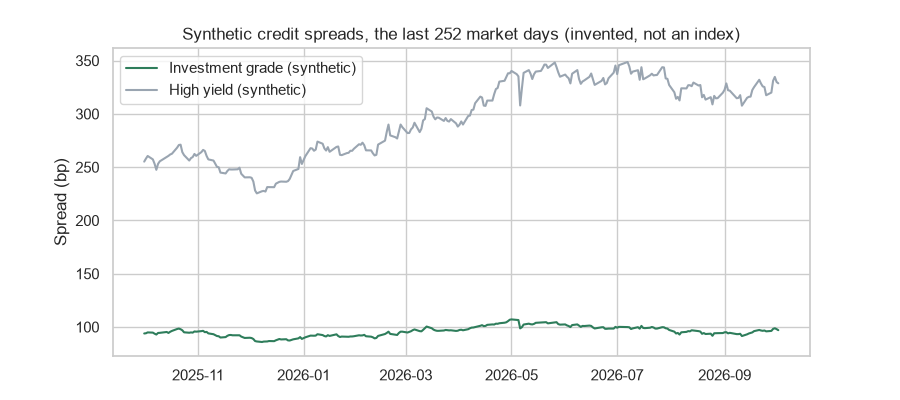

In [27]:
# read the file back and show it as a page
from IPython.display import HTML, display

page = html_path.read_text(encoding='utf-8')
display(HTML(page))

The same file opens in your browser with PowerShell's `Invoke-Item`, which opens a file with its own program (Bring It Home).

### Check It as Text

In [28]:
# the headings in order: (.+?) is Course 1's lazy group, which stops at the first </h2>
re.findall(r'<h2>(.+?)</h2>', page)

['levels',
 'curve',
 'slopes_flies',
 'book',
 'Treasury curve',
 'Synthetic credit spreads']

In [29]:
# plain text checks on the page
checks = {'the date line': f'<p>As of {AS_OF}.</p>' in page,
          'the disclaimer': md.DISCLAIMER in page,
          'the sources': 'Daily Treasury Par Yield Curve Rates' in page,
          'the synthetic label': 'The credit spreads and the book are synthetic.' in page,
          'four tables': page.count('<table') == 4,
          'two pictures': page.count('data:image/png;base64,') == 2,
          'no home folder or work folder': str(Path.home()) not in page and work.name not in page}
assert all(checks.values()), checks
print(f'{sum(checks.values())} of {len(checks)} checks pass')

7 of 7 checks pass


**One function writes one self-contained file, title to sources, and seven plain checks prove what is on it.**

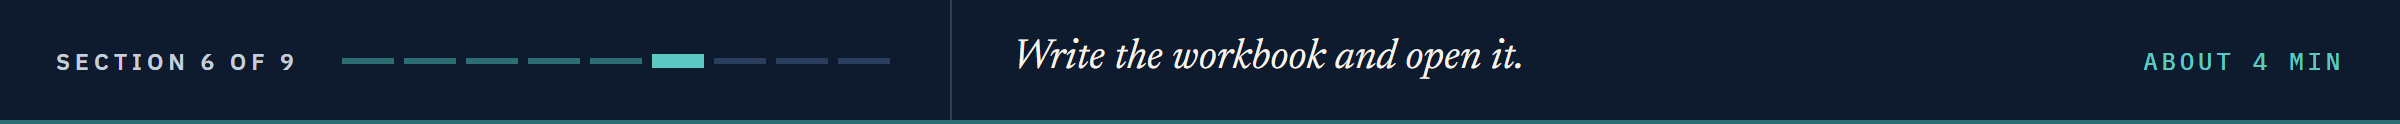

## 14.6 The Workbook, Opened in Excel

The note asks for a workbook to check in Excel.
`write_snapshot_excel` puts an `about` sheet first, with the date and the sources, then one sheet per table.
It uses `pd.ExcelWriter`, as Course 2's Portfolio Aggregation and Scenarios did.

### `write_snapshot_excel`

In [30]:
%%writefile -a marketdata.py


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Appending to marketdata.py


### Read It Back

In [31]:
# reload, write the workbook beside the page, then read every sheet back
importlib.reload(md)
xlsx_path = md.write_snapshot_excel(tables, Path('snapshots') / f'snapshot_{AS_OF}.xlsx')
# sheet_name=None reads every sheet into a dictionary of tables, as in Course 1
back = pd.read_excel(xlsx_path, sheet_name=None, index_col=0)
print(list(back), 'as of', back['about'].loc['as_of', 'value'])
print({name: len(table) for name, table in back.items()})

['about', 'levels', 'curve', 'slopes_flies', 'book'] as of 2026-10-02
{'about': 4, 'levels': 6, 'curve': 14, 'slopes_flies': 5, 'book': 18}


In [32]:
# the levels sheet against the table it came from, equal to 12 significant digits
pd.testing.assert_frame_equal(back['levels'], tables['levels'], check_exact=False, rtol=1e-12,
                              check_dtype=False)
print('levels: equal')

levels: equal


**Predict 3**

Q. The writer sets no number format and no column width. In Excel, the book sheet's total face, 489,000,000, shows as:

A) 489000000
B) 4.89E+08
C) `########`

### What Excel Shows

**Excel side by side.** The workbook as written, opened in Excel 16.0 (build 20430) read-only and closed unsaved.
In the book sheet the index is column A, `by` is B, the DV01 G, and the what-if H.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">The sheets</td><td align="left"><code>list(back)</code></td><td align="left">the tabs</td><td align="left"><code>about</code>, <code>levels</code>, <code>curve</code>, <code>slopes_flies</code>, <code>book</code></td></tr>
<tr><td align="left">Number format</td><td align="left">none set</td><td align="left">General</td><td align="left">no <code>####</code> anywhere</td></tr>
<tr><td align="left">Total face</td><td align="left"><code>489000000</code></td><td align="left">General, standard width</td><td align="left">shows <code>4.89E+08</code>, holds 489000000</td></tr>
<tr><td align="left">Consumer's value</td><td align="left"><code>56629597.5</code></td><td align="left">General</td><td align="left">shows 56629598, holds 56629597.5</td></tr>
<tr><td align="left">The curve's change</td><td align="left"><code>chg_bp</code></td><td align="left"><code>=(D2-C2)*100</code> in F, filled down</td><td align="left">within 8.9e-16 bp of column E</td></tr>
<tr><td align="left">DV01 by sector</td><td align="left"><code>dv01_usd</code></td><td align="left"><code>=SUMIFS(G2:G19,B2:B19,"sector")</code></td><td align="left">306996.110402</td></tr>
<tr><td align="left">DV01 by rating</td><td align="left"><code>dv01_usd</code></td><td align="left"><code>=SUMIFS(G2:G19,B2:B19,"rating bucket")</code></td><td align="left">306996.110402</td></tr>
<tr><td align="left">The what-if, both ways</td><td align="left"><code>mv_change_usd</code></td><td align="left"><code>=SUMIFS(H2:H19,B2:B19,"sector")</code>, then <code>"rating bucket"</code></td><td align="left">-1193297.89</td></tr>
</table>
<br clear="left">

B: Excel shows `4.89E+08`, and the cell holds 489000000.

### Two More Tests

The page test draws one small chart with `Figure(figsize=(4, 3))`, a chart made with no screen, as a script needs.

In [33]:
%%writefile -a test_marketdata.py


def test_html_contains_as_of_and_disclaimer(tmp_path):
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-10-02", SNAPSHOT_UNITS)
    # one small chart of the curve, drawn without a screen
    figure = Figure(figsize=(4, 3))
    axes = figure.subplots()
    axes.plot(tables["curve"]["years"], tables["curve"]["as_of_pct"])
    path = md.write_snapshot_html(tables, {"curve": figure}, tmp_path / "snapshot.html", "Daily market snapshot")
    text = path.read_text(encoding="utf-8")
    assert "As of 2026-10-02." in text
    assert md.DISCLAIMER in text
    assert "synthetic" in text and "data:image/png;base64," in text
    assert text.count("<table") == 4


def test_excel_round_trip(tmp_path):
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-10-02", SNAPSHOT_UNITS)
    path = md.write_snapshot_excel(tables, tmp_path / "snapshot.xlsx")
    back = pd.read_excel(path, sheet_name=None, index_col=0)
    # the about sheet first, with the as-of date and the disclaimer, then one sheet per table
    assert list(back) == ["about", *tables]
    assert back["about"].loc["as_of", "value"] == "2026-10-02"
    assert back["about"].loc["disclaimer", "value"] == md.DISCLAIMER
    for name, table in tables.items():
        assert len(back[name]) == len(table)
    levels = back["levels"]
    levels.index.name = tables["levels"].index.name
    pd.testing.assert_frame_equal(levels, tables["levels"], check_exact=False, rtol=1e-12, check_dtype=False)

Appending to test_marketdata.py


In [34]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................................                  [100%]
55 passed in 0.50s



**The workbook opens in Excel with its date on the first sheet, and Excel's own `SUMIFS` gives the book's DV01 back to the sixth decimal.**

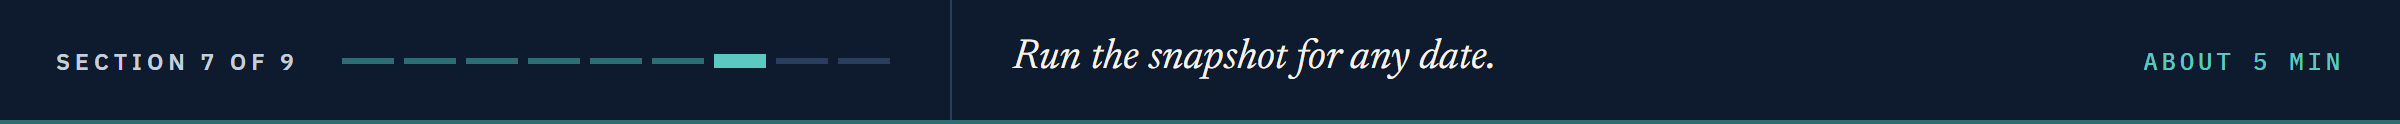

## 14.7 `snapshot.py`: One Command, Any Date

A **script** is a `.py` file started from PowerShell, `python snapshot.py`, not imported.

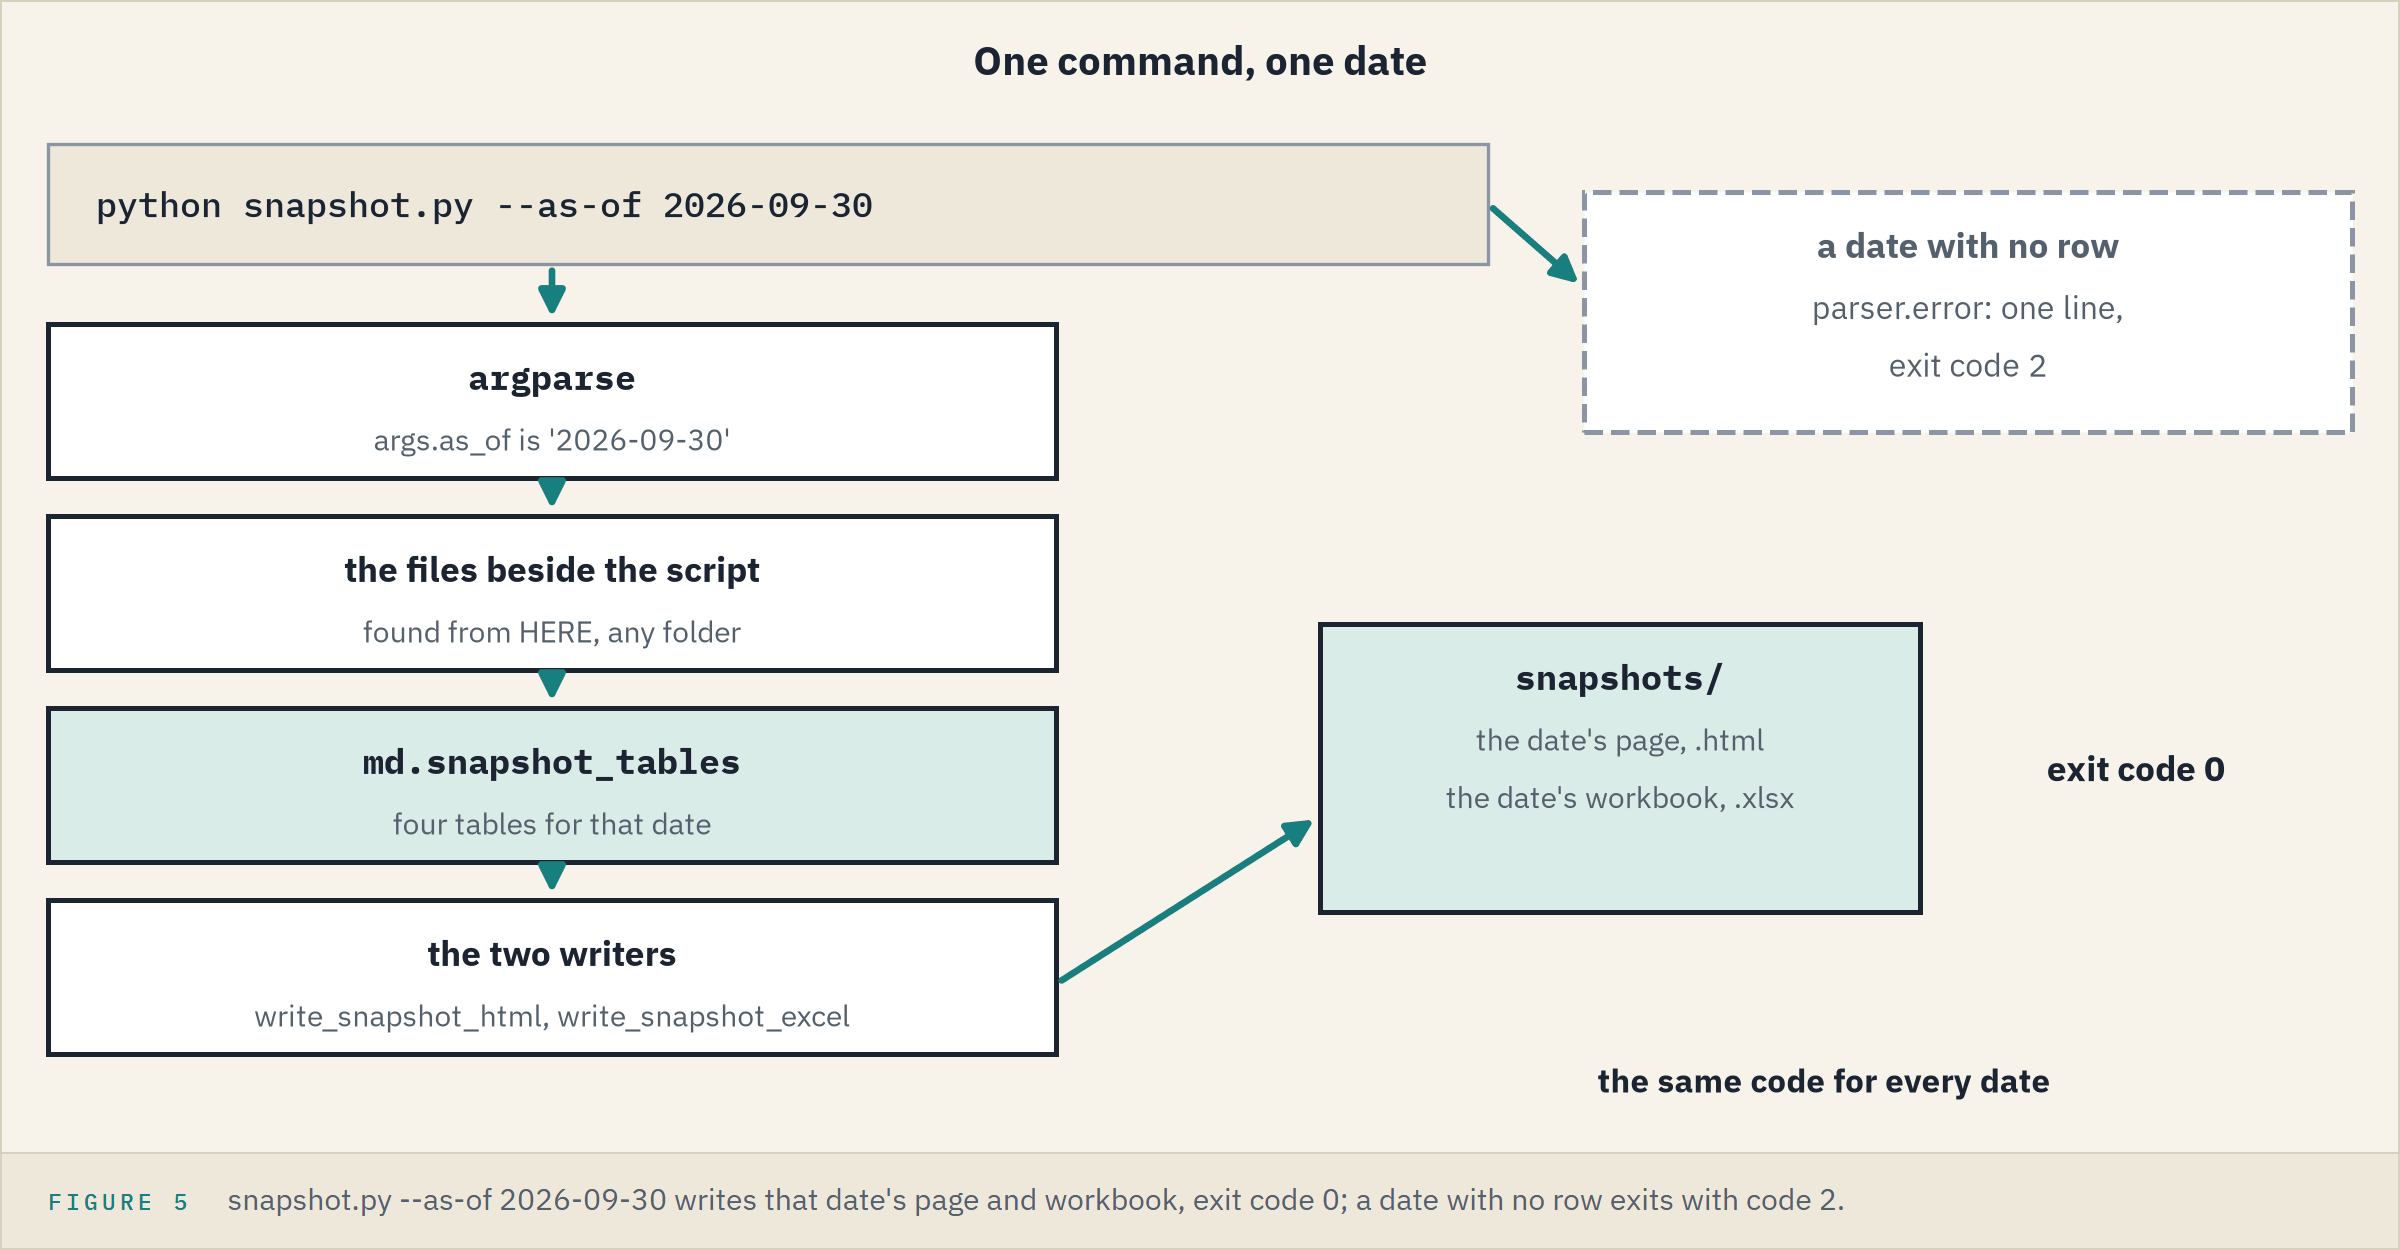

`argparse` reads the command line, and `--as-of 2026-09-30` arrives as `args.as_of`, the hyphen an underscore.

`HERE = Path(__file__).resolve().parent` is the script's own folder, so it runs from any folder.

`if __name__ == "__main__":` runs `main()` only when the file is started as a script, as in Course 1's From Notebook to Module.

An **exit code** says how a run went, 0 for success and anything else for not, and `run.returncode` holds it.

### The Script

In [35]:
%%writefile snapshot.py
"""snapshot.py: write the daily market snapshot for one market date, as HTML and as Excel.

Usage, from any folder:
    python snapshot.py --as-of 2026-10-02
    python snapshot.py                      (the last date in the market data)

It reads the Treasury file, the synthetic spreads, and the synthetic book from the folder this file is in, and
writes snapshots/snapshot_YYYY-MM-DD.html and .xlsx there. It describes the data and forecasts nothing.
"""
import argparse
from pathlib import Path

import pandas as pd
from matplotlib.figure import Figure

import marketdata as md

# the folder this file is in, whichever folder the script is started from
HERE = Path(__file__).resolve().parent
# the market columns on the levels table, and their units
UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}


def load_market() -> pd.DataFrame:
    """The Treasury file (percent) joined to the synthetic spreads (bp), one row per market date."""
    options = {"parse_dates": ["date"], "index_col": "date", "float_precision": "round_trip"}
    treasury = pd.read_csv(HERE / "treasury_par_yields.csv", **options)
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", **options)
    return treasury.join(spreads, validate="one_to_one")


def charts(tables: dict[str, pd.DataFrame], market: pd.DataFrame) -> dict[str, Figure]:
    """The two charts, drawn without a screen: the curve on both days, and the synthetic spreads."""
    as_of = pd.Timestamp(tables["levels"].attrs["as_of"])
    previous = market.index[market.index.get_loc(as_of) - 1]
    curve = tables["curve"]
    curve_figure = Figure(figsize=(7, 3.5))
    axes = curve_figure.subplots()
    axes.plot(curve["years"], curve["previous_pct"], marker="o", markersize=3, label=f"{previous:%Y-%m-%d}")
    axes.plot(curve["years"], curve["as_of_pct"], marker="o", markersize=3, label=f"{as_of:%Y-%m-%d}")
    axes.set_title(f"Treasury par curve, {as_of:%Y-%m-%d} and the previous market date")
    axes.set_xlabel("Tenor (years)")
    axes.set_ylabel("Yield (percent)")
    axes.legend()
    curve_figure.tight_layout()

    recent = market.loc[:as_of, ["ig_spread_bp", "hy_spread_bp"]].tail(252)
    spread_figure = Figure(figsize=(7, 3.5))
    axes = spread_figure.subplots()
    axes.plot(recent.index, recent["ig_spread_bp"], label="Investment grade (synthetic)")
    axes.plot(recent.index, recent["hy_spread_bp"], label="High yield (synthetic)")
    axes.set_title("Synthetic credit spreads, the last 252 market days (invented, not an index)")
    axes.set_ylabel("Spread (bp)")
    axes.legend()
    spread_figure.autofmt_xdate()
    spread_figure.tight_layout()
    return {"Treasury curve": curve_figure, "Synthetic credit spreads": spread_figure}


def main() -> None:
    parser = argparse.ArgumentParser(description="Write the daily market snapshot as HTML and Excel.")
    parser.add_argument("--as-of", help="the market date, YYYY-MM-DD (default: the last date in the market data)")
    args = parser.parse_args()

    market = load_market()
    book = pd.read_csv(HERE / "holdings.csv")
    as_of = args.as_of or f"{market.index[-1]:%Y-%m-%d}"
    try:
        tables = md.snapshot_tables(market, book, as_of, UNITS)
    except ValueError as error:
        # a one-line message and exit code 2, with no traceback: a traceback would print this file's full path
        parser.error(str(error))

    # the date as the tables carry it, YYYY-MM-DD, names both files
    as_of = tables["levels"].attrs["as_of"]
    out = HERE / "snapshots"
    out.mkdir(exist_ok=True)
    md.write_snapshot_html(tables, charts(tables, market), out / f"snapshot_{as_of}.html", f"Daily market snapshot, {as_of}")
    md.write_snapshot_excel(tables, out / f"snapshot_{as_of}.xlsx")
    print(f"snapshot for {as_of}: wrote snapshots/snapshot_{as_of}.html and snapshots/snapshot_{as_of}.xlsx")


if __name__ == "__main__":
    main()

Writing snapshot.py


`args.as_of or ...` takes the first value that is not empty, so a run with no `--as-of` gets the file's last date.
`autofmt_xdate()` tilts the spread chart's date labels so they do not overlap.

### Its Help

In [36]:
# subprocess and sys came in with the pytest cell: the script run as PowerShell would run it
help_run = subprocess.run([sys.executable, 'snapshot.py', '--help'], cwd=work,
                          capture_output=True, text=True)
print(help_run.stdout)

usage: snapshot.py [-h] [--as-of AS_OF]

Write the daily market snapshot as HTML and Excel.

options:
  -h, --help     show this help message and exit
  --as-of AS_OF  the market date, YYYY-MM-DD (default: the last date in the
                 market data)



**Predict 4**

Q. 14.5 and 14.6 left two files for 2 October in `snapshots`. Run the script for 2 October, then for 30 September. How many files are in `snapshots` then? Write down a number.

### Two Dates

In [37]:
# the script for each date, its exit code checked, then the folder's files
for as_of in ['2026-10-02', '2026-09-30']:
    run = subprocess.run([sys.executable, 'snapshot.py', '--as-of', as_of], cwd=work,
                         capture_output=True, text=True)
    assert run.returncode == 0, run.stderr
    print(run.stdout.strip())
sorted(path.name for path in Path('snapshots').glob('*'))

snapshot for 2026-10-02: wrote snapshots/snapshot_2026-10-02.html and snapshots/snapshot_2026-10-02.xlsx
snapshot for 2026-09-30: wrote snapshots/snapshot_2026-09-30.html and snapshots/snapshot_2026-09-30.xlsx


['snapshot_2026-09-30.html',
 'snapshot_2026-09-30.xlsx',
 'snapshot_2026-10-02.html',
 'snapshot_2026-10-02.xlsx']

Four.
The run for 2 October wrote over the two files of the same names.

### A Date With No Row

In [38]:
# Labor Day again, now through the script
bad_run = subprocess.run([sys.executable, 'snapshot.py', '--as-of', '2026-09-07'], cwd=work,
                         capture_output=True, text=True)
print('exit code', bad_run.returncode)
print(bad_run.stderr)

exit code 2
usage: snapshot.py [-h] [--as-of AS_OF]
snapshot.py: error: 2026-09-07 is not a market date: market has no row for it



One line and exit code 2, with no traceback, which would print the script's full path.

### Rerun, Do Not Redo

In [39]:
# each date's levels sheet, read back from its own workbook
two_days = {day: pd.read_excel(Path('snapshots') / f'snapshot_{day}.xlsx', sheet_name='levels',
                               index_col=0)[['level', 'zscore', 'pct_rank']]
            for day in ['2026-09-30', '2026-10-02']}
# pd.concat of a dictionary, as notebook 03's align: each key heads its group of columns
side_by_side = pd.concat(two_days, axis=1)
side_by_side.round(2)

2026-09-30                 2026-10-02                
                  level zscore pct_rank      level zscore pct_rank
series                                                            
2 Yr               4.88   2.73    99.21       4.83   2.51    98.02
5 Yr               5.09   2.99   100.00       5.06   2.80    99.60
10 Yr              5.29   3.25   100.00       5.28   3.08    99.60
30 Yr              5.64   3.26   100.00       5.63   3.08    99.60
ig_spread_bp      98.80   0.61    73.02      97.00   0.22    61.11
hy_spread_bp     334.70   1.09    82.94     328.70   0.90    73.81

The 10 Yr shows 5.29 on 30 September and 5.28 on 2 October.

**One command writes the page and the workbook for any market date, and the code did not change between the two.**

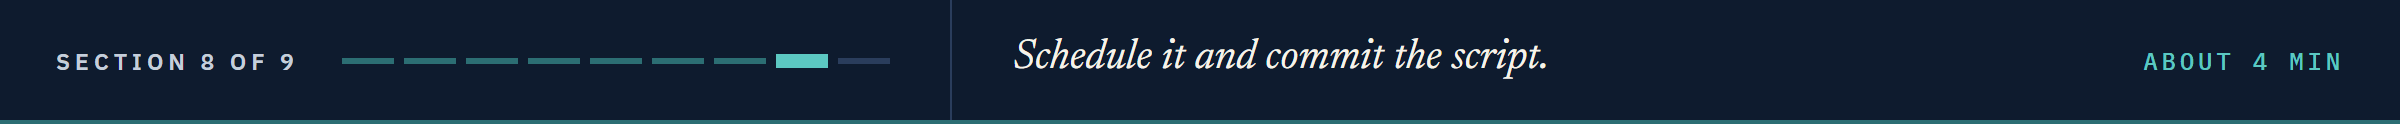

## 14.8 Every Morning, and the Record

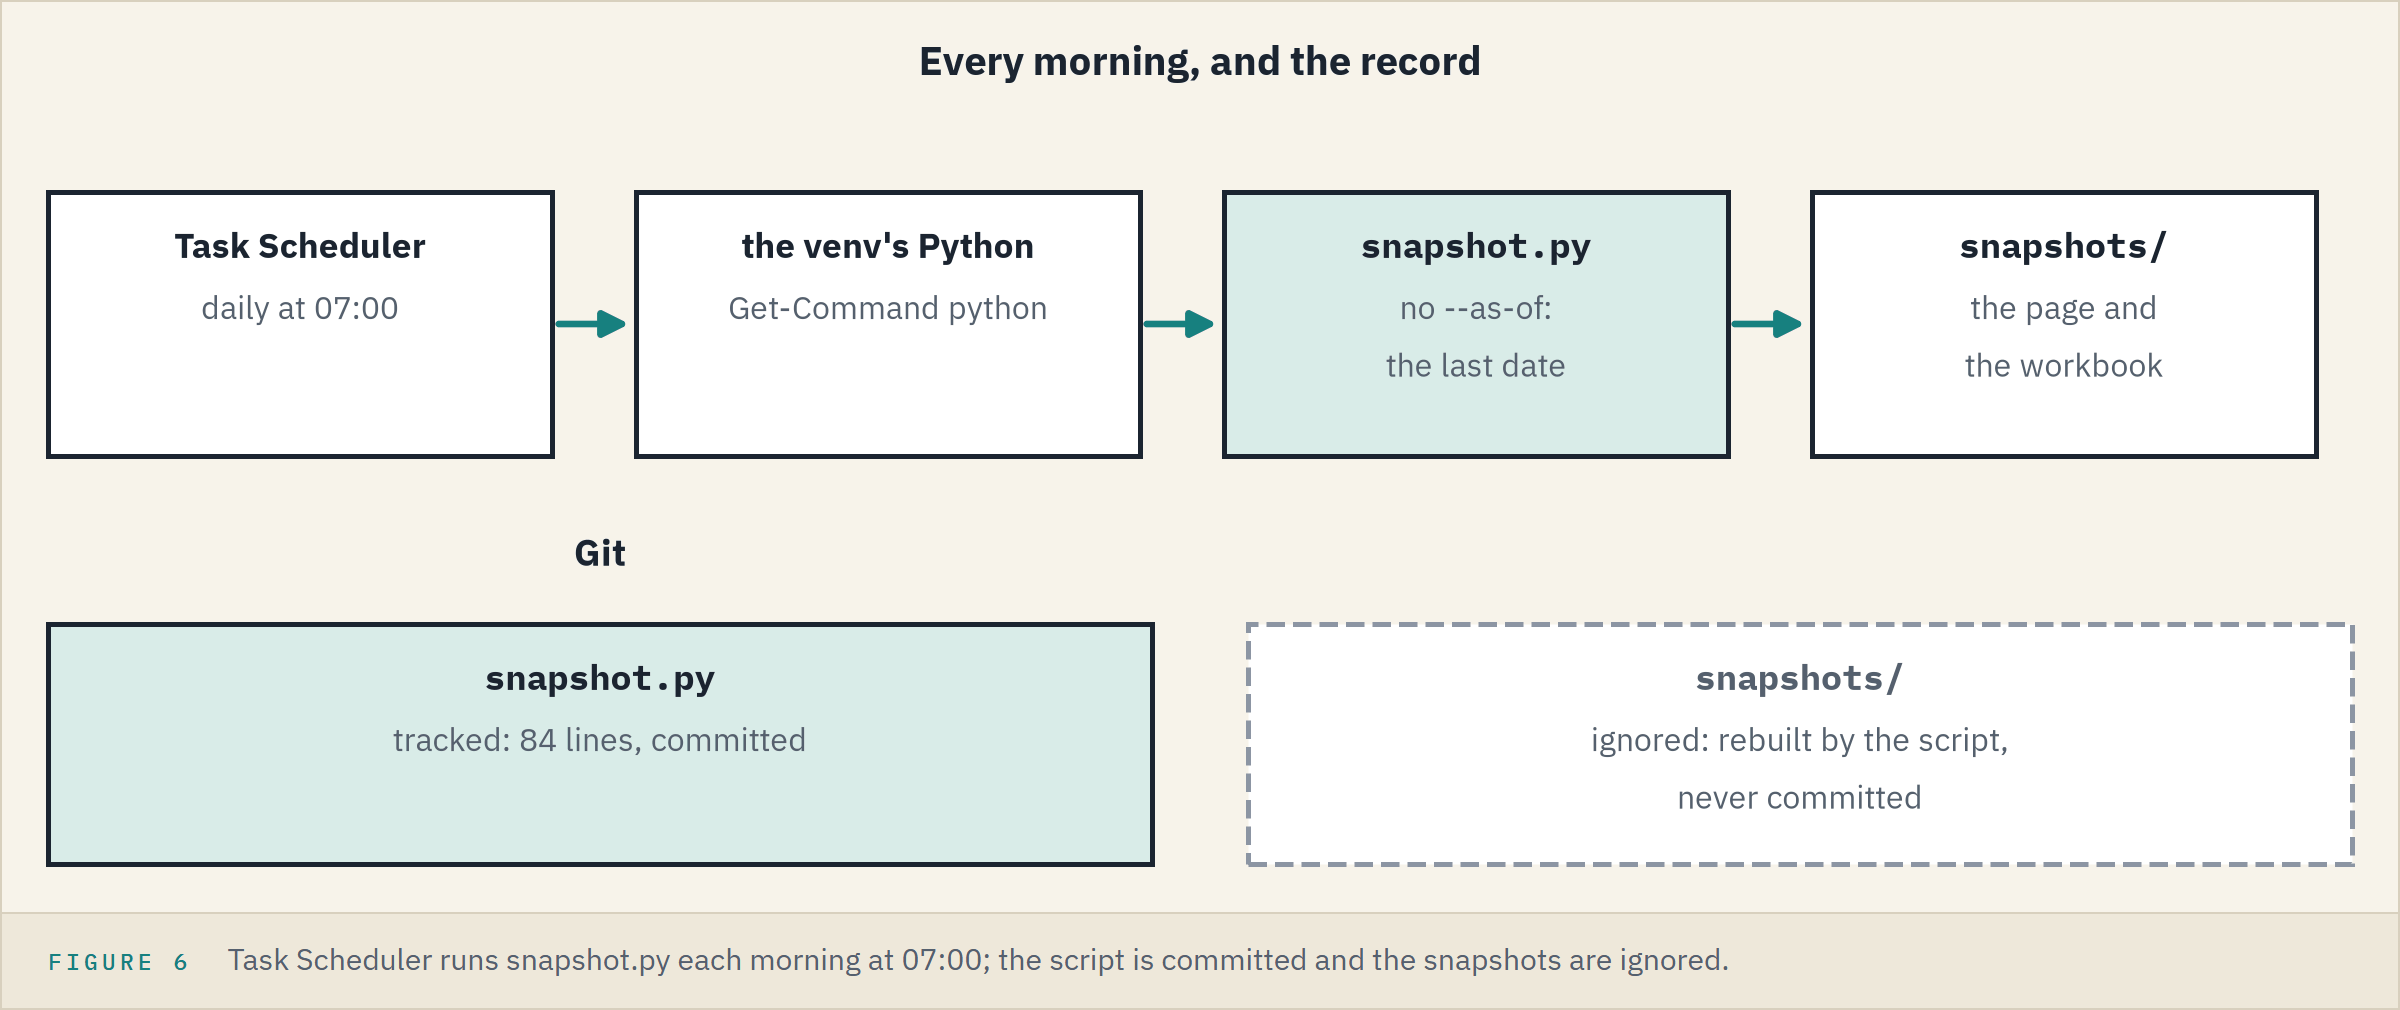

Windows' **Task Scheduler** runs a command at a set time, and `schtasks` is its command-line tool.
These lines are text for your own machine, never run here.
At work, your firm's policy decides whether a scheduled task may run.

```powershell
# the full path of the venv's Python (the course's .venv active)
$python = (Get-Command python).Source
# /TN names the task, /SC DAILY and /ST set when, /TR is the command
schtasks /Create /TN "pfi_daily_snapshot" /SC DAILY /ST 07:00 /TR "'$python' '$HOME\projects\my_bondmath\snapshot.py'"
# look at it, run it once now, delete it
schtasks /Query /TN "pfi_daily_snapshot"
schtasks /Run /TN "pfi_daily_snapshot"
schtasks /Delete /TN "pfi_daily_snapshot" /F
```

`schtasks /Create /?` says a path with spaces needs a second set of quotes inside the first, and single quotes will do.
The course's files stop on 2 October, so every run writes the same page until the data is refreshed, the capstone's job.

### What Git Sees

In [40]:
!git -C "{work}" status --short

 M marketdata.py
 M test_marketdata.py
?? snapshot.py
?? snapshots/


### Keep the Pages Out

In [41]:
%%writefile -a .gitignore
# the snapshot outputs: rebuilt by python snapshot.py, never committed
snapshots/

Appending to .gitignore


In [42]:
!git -C "{work}" status --short --ignored

 M .gitignore
 M marketdata.py
 M test_marketdata.py
?? snapshot.py
!! __pycache__/
!! bondmath.py
!! course3_excel_reference.csv
!! course3_fred_format_dgs10.json
!! course3_fred_format_dgs2.json
!! course3_synthetic_spreads.csv
!! holdings.csv
!! ratings.csv
!! snapshots/
!! trade_blotter.csv
!! treasury_par_yields.csv


`snapshots/` is ignored now.
The data files and `bondmath.py` show `!!` too, from the work folder's own ignore list.

### Commit the Day

A second `-m` adds a body under the subject.
`git log --stat -1` shows the last commit with each file's count of changed lines.

In [43]:
# the day's subject, as start_day records it, and a body; IPython fills in {subject} and {body}
subject = ('Notebook 14: snapshot_tables, write_snapshot_html, write_snapshot_excel, '
           'and snapshot.py')
body = 'The pages are rebuilt by python snapshot.py, so snapshots/ is ignored.'
!git -C "{work}" diff --stat
!git -C "{work}" add .gitignore marketdata.py test_marketdata.py snapshot.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"
!git -C "{work}" log --stat -1

 .gitignore         |   2 +
 marketdata.py      | 157 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py |  62 +++++++++++++++++++++
 3 files changed, 221 insertions(+)
commit d20a0477c2524154d29765e640ced5799a384d1c
Author: Course Student <student@example.com>
Date:   Wed Sep 30 09:00:00 2026 +0000

    Notebook 14: snapshot_tables, write_snapshot_html, write_snapshot_excel, and snapshot.py
    
    The pages are rebuilt by python snapshot.py, so snapshots/ is ignored.

 .gitignore         |   2 +
 marketdata.py      | 157 +++++++++++++++++++++++++++++++++++++++++++++++++++++
 snapshot.py        |  84 ++++++++++++++++++++++++++++
 test_marketdata.py |  62 +++++++++++++++++++++
 4 files changed, 305 insertions(+)


**Task Scheduler can run the command every morning, and Git keeps the 84 lines that write the pages and none of the pages.**

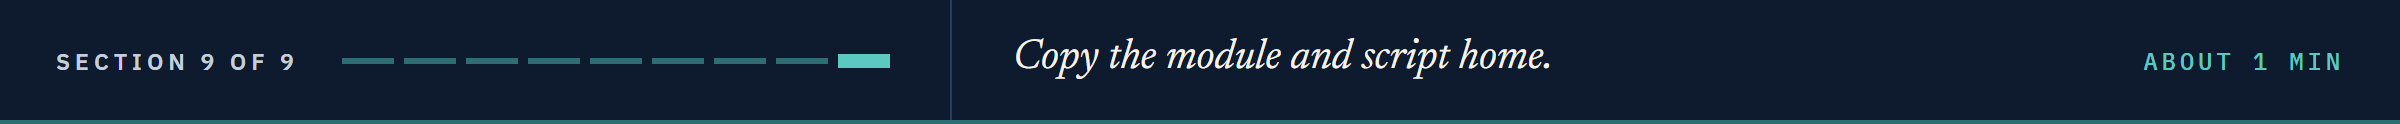

## Bring It Home

Copy the work folder's module, tests and script into your own `my_bondmath` folder, test them there, run the script, and commit.
The copy replaces your files, so anything of your own must be in the work folder first.
The script reads the synthetic spreads, so copy them too; the Treasury file and the book are there since notebooks 04 and 11.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_14_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py", "$work\snapshot.py" .
Copy-Item "$work\course3_synthetic_spreads.csv" .
Add-Content .gitignore "snapshots/"
python -m pytest -q test_marketdata.py
python snapshot.py
Invoke-Item snapshots\snapshot_2026-10-02.html
git status --short
git add .gitignore marketdata.py test_marketdata.py snapshot.py
git commit -m "Notebook 14: snapshot_tables, write_snapshot_html, write_snapshot_excel, and snapshot.py"
```

pytest shows 55 passed, and the page opens in your browser.
In Colab, download the three files and the `snapshots` folder from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Build a one-page snapshot's tables for any market date from rows on or before it only.
* Put the book's DV01 by sector and rating beside a what-if of the day's curve move, labelled as one.
* Write a self-contained HTML page and an Excel workbook, and check both as data.
* Prove a date-driven report reads nothing after its date.
* Turn notebook code into a script with `argparse`, run it for any date, and read its exit code.
* Schedule a script with Task Scheduler and keep its outputs out of Git.

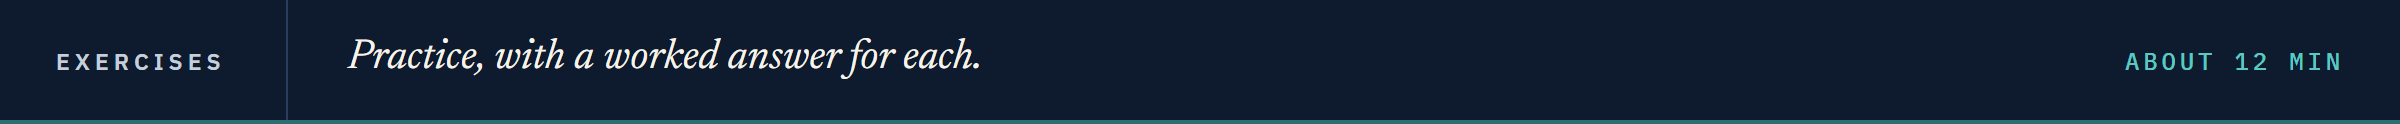

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`.

In [44]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

Q. Build the snapshot for 2026-09-15. Store the 10 Yr level in **ex1_level** and the book's what-if change in value, rounded to cents, in **ex1_book_change**.

In [45]:
ex1_level = ...
ex1_book_change = ...

In [46]:
check('Exercise 1 the 10 Yr level', ex1_level, 5.0)
check('Exercise 1 the book what-if', ex1_book_change, -872595.85)

Exercise 1 the 10 Yr level: not attempted yet
Exercise 1 the book what-if: not attempted yet


### Exercise 2

Q. The slopes table carries 5s30s over 252 rows. Make 5s30s with `md.slope_bp`, take its `md.summary_table` row for 2026-10-02 with `window=63`, rename the row `5s30s (63 rows)` with `.rename(index=...)`, and add it under the slopes table with `pd.concat`. Store the new table's number of rows in **ex2_rows** and the new row's z-score in **ex2_zscore**.

In [47]:
ex2_rows = ...
ex2_zscore = ...

In [48]:
check('Exercise 2 the rows', ex2_rows, 6)
check('Exercise 2 the 63-row z-score', ex2_zscore, -1.0784129299830423)

Exercise 2 the rows: not attempted yet
Exercise 2 the 63-row z-score: not attempted yet


### Exercise 3

Q. Add `snapshot_file_name(as_of, ext)` to the module, docstring first. It returns `snapshot_YYYY-MM-DD.ext` for `ext` either `"html"` or `"xlsx"`, and raises `ValueError` for anything else. Add `test_snapshot_file_name_sorts_by_date`: two names, three names that sort as text in date order, and the `ValueError`. Run pytest, reload, and store `md.snapshot_file_name("2026-09-30", "xlsx")` in **ex3_name**.

In [49]:
%%writefile -a marketdata.py


# Exercise 3: write snapshot_file_name(as_of, ext) below this line

Appending to marketdata.py


In [50]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_snapshot_file_name_sorts_by_date() below this line

Appending to test_marketdata.py


In [51]:
# run pytest as in the lesson, reload the module, then call your function
ex3_name = ...

In [52]:
check('Exercise 3 the file name', ex3_name, 'snapshot_2026-09-30.xlsx')

Exercise 3 the file name: not attempted yet


### Exercise 4: AI check

You asked an assistant for the top of the snapshot, each series' level and one-day change as of a date, with the docstring below as the prompt.
The function came back, written for this course in the style of an assistant's answer; it runs and holds one bug.

In [53]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
def snapshot_levels(market, as_of, units):
    """The level and one-day change of each series as of `as_of`, from rows on or before it only.

    Units: units[column] is "pct" (a yield, in percent) or "bp" (a spread); level in that
    unit, chg_1d_bp in bp. Convention: the level is the value on as_of, which must be a market
    date (a row of market); the change is from the previous observation. A row after as_of must
    never change the answer.
    """
    # today's row and the one before it
    today = market.iloc[-1]
    previous = market.iloc[-2]
    rows = {}
    for column, unit in units.items():
        # yields in percent move in bp after x 100; spreads are in bp already
        scale = 100 if unit == "pct" else 1
        change_bp = (today[column] - previous[column]) * scale
        rows[column] = {"level": today[column], "chg_1d_bp": change_bp}
    return pd.DataFrame.from_dict(rows, orient="index")

Q. Predict first: what level does it give the 10 Yr for 2026-09-30? The file runs to 2026-10-02.

In [54]:
# the assistant's function for 30 September
snapshot_levels(market, '2026-09-30', SNAPSHOT_UNITS)

,level,chg_1d_bp
2 Yr,4.83,5.0
5 Yr,5.06,5.0
10 Yr,5.28,4.0
30 Yr,5.63,2.0
ig_spread_bp,97.00,-1.0
hy_spread_bp,328.70,-1.3


Q. Test it against its docstring before you trust it.

In [55]:
# the test, written from the docstring
levels_30 = snapshot_levels(market, '2026-09-30', SNAPSHOT_UNITS)
assert levels_30.loc['10 Yr', 'level'] == 5.29, 'the 10 Yr on 2026-09-30 was 5.29 percent'
# a row after the as-of date must change nothing: the same call on the market cut there
cut_market = market.loc[:'2026-09-30']
pd.testing.assert_frame_equal(levels_30, snapshot_levels(cut_market, '2026-09-30', SNAPSHOT_UNITS))
print("The level is 2026-09-30's, and later rows change nothing")

AssertionError: the 10 Yr on 2026-09-30 was 5.29 percent

Q. Read the message, fix the function in its cell, and run it and the test again until the test passes. Store the fixed function's 10 Yr level for 2026-09-30 in **ex4_level** and its one-day change in bp in **ex4_change**.

In [56]:
ex4_level = ...
ex4_change = ...

In [57]:
check('Exercise 4 the 10 Yr level', ex4_level, 5.29)
check('Exercise 4 the one-day change', ex4_change, 3.000000000000025)

Exercise 4 the 10 Yr level: not attempted yet
Exercise 4 the one-day change: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Closes and moves</td><td align="left">10 Yr 5.28 percent, up 4 bp on the day and 49 bp on the month; synthetic HY 328.7 bp, down 1.3 bp</td></tr>
<tr><td align="left">Each in its own year</td><td align="left">10 Yr z-score 3.08, 99.6 percent at or below; 2s10s 45 bp, 28.2 percent</td></tr>
<tr><td align="left">The book</td><td align="left">DV01 306,996.11 dollars per bp; the what-if -1,193,297.89 dollars, about 3.9 bp</td></tr>
<tr><td align="left">Page and workbook</td><td align="left"><code>snapshot_2026-10-02.html</code> and <code>.xlsx</code>, both checked</td></tr>
<tr><td align="left">Any date</td><td align="left"><code>python snapshot.py --as-of</code>, run for two dates</td></tr>
<tr><td align="left">Every morning, the record</td><td align="left"><code>schtasks</code> as text; <code>snapshot.py</code> committed, <code>snapshots/</code> ignored</td></tr>
</table>
<br clear="left">

Be proud: a desk report built from functions you wrote and tested, for any date, with nothing read from the future.

Next: the Course 3 Capstone, where a vendor's extract is cleaned, proved and put through this snapshot.

[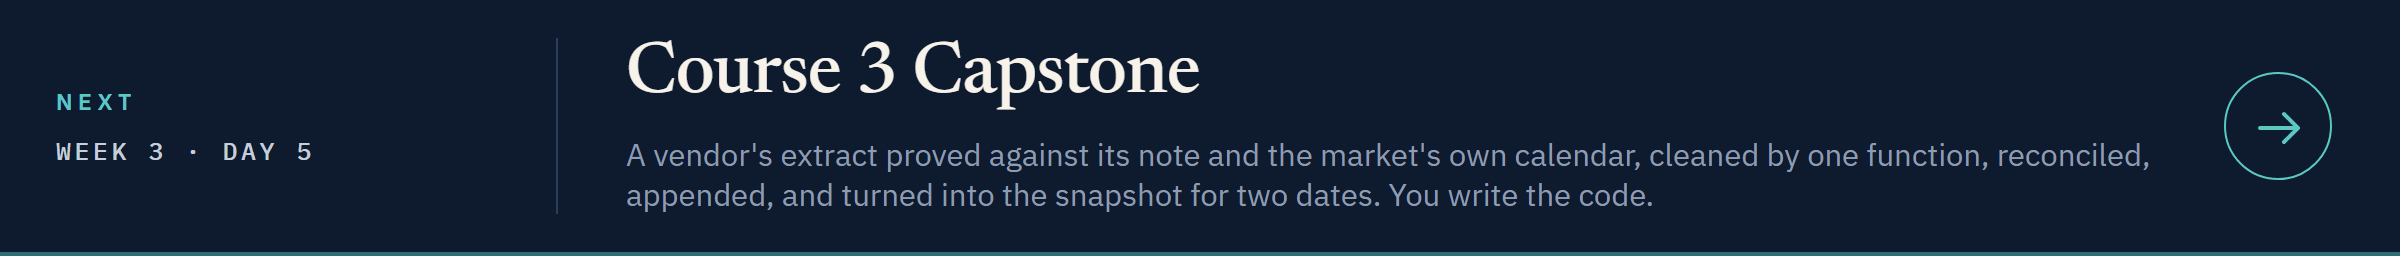](../day5/course3_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week3/day5/course3_capstone.ipynb)